# e1121223 — Fraudulent Bitcoin Transaction Detection

**DIVERSE-GRAPH-V11.** Run all cells in order with the four supplied CSVs and pinned requirements.
The pipeline compares tree models and graph-risk features using chronological validation.
All models are fitted afresh; each run saves a folder and ZIP under `outputs/`.


In [1]:
# Uncomment once if dependencies are not installed, then restart the kernel.
#%pip install -r requirements.txt

## 1. Configuration and reproducibility

Set data paths, fixed trial counts, recency weighting and seeds below. Defaults use **104 Optuna
trials**, six temporal cutoffs and final seeds **42, 137, 2026**. Full runtime may exceed two hours.

`RECENCY_MODE` selects uniform weights or exponential decay. Smaller half-lives emphasize recent
transactions. References and the graph teacher retain their declared settings. The notebook version,
input hashes and environment are saved; a version mismatch requires reloading from disk.


In [2]:
import os
SEED = 42
N_THREADS = 8  # Fixed across runs; lower explicitly if required by your device.
# Set these before importing numerical libraries in a fresh kernel.
os.environ["OMP_NUM_THREADS"] = str(N_THREADS)
os.environ["MKL_NUM_THREADS"] = str(N_THREADS)
os.environ["OPENBLAS_NUM_THREADS"] = str(N_THREADS)

import ast
import gc
import hashlib
import importlib.metadata
import json
import platform
import random
import sys
import time
from pathlib import Path
from datetime import datetime

import joblib
import nbformat
import shutil
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy.sparse as sp
from scipy.sparse.csgraph import connected_components
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (roc_auc_score, average_precision_score, accuracy_score,
                             precision_score, recall_score, f1_score,
                             RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from IPython.display import display

try:
    import lightgbm as lgb
    import xgboost as xgb
    import optuna
except ImportError as exc:
    raise ImportError("Install requirements.txt in this kernel, then restart it.") from exc

random.seed(SEED)
np.random.seed(SEED)
optuna.logging.set_verbosity(optuna.logging.WARNING)

DATA_DIR = Path.cwd()           # Edit if the CSV files are elsewhere.
NOTEBOOK_VERSION = "DIVERSE-GRAPH-V11"


def verify_notebook_version(notebook, expected_version, notebook_path):
    """Read the version assignment wherever its code cell is located."""
    saved_versions = set()
    for cell in notebook.cells:
        if cell.cell_type != "code":
            continue
        try:
            statements = ast.parse(cell.source).body
        except SyntaxError:
            continue  # For example, a standalone %pip installation cell.
        for statement in statements:
            if isinstance(statement, ast.Assign):
                targets, value = statement.targets, statement.value
            elif isinstance(statement, ast.AnnAssign):
                targets, value = [statement.target], statement.value
            else:
                continue
            if any(isinstance(target, ast.Name) and target.id == "NOTEBOOK_VERSION" for target in targets):
                if isinstance(value, ast.Constant) and isinstance(value.value, str):
                    saved_versions.add(value.value)
    if saved_versions != {expected_version}:
        saved_text = ", ".join(sorted(saved_versions)) or "no literal version assignment found"
        raise RuntimeError(
            f"Notebook version mismatch. Running cell: {expected_version}; saved file: {saved_text}. "
            f"File: {notebook_path}. Reload/revert the notebook from disk without overwriting it "
            "with the stale editor copy, then restart the kernel and Run All. "
            "Restarting the kernel alone does not reload notebook cells."
        )
    return expected_version

source_path = (Path.cwd() / "e1121223.ipynb").resolve()
source_nb = nbformat.read(source_path, as_version=4)
verify_notebook_version(source_nb, NOTEBOOK_VERSION, source_path)
print(f"Verified notebook version: {NOTEBOOK_VERSION}")

# Training sample weights, NOT validation-window weights.
# "search": compare equal weighting and half-lives 4, 8, 12, 16, 24, 32.
# "recent": restrict new candidates to stronger weighting (4, 8, 12).
# "fixed": use FIXED_HALF_LIFE for every new candidate.
# "uniform": equal weights for every new candidate.
# Historical references keep their original window/decay settings in every mode.
RECENCY_MODE = "search"
FIXED_HALF_LIFE = 8

def recency_choices(mode, fixed_half_life):
    choices = {"search": [None, 4, 8, 12, 16, 24, 32],
               "recent": [4, 8, 12], "uniform": [None]}
    if mode == "fixed":
        if (isinstance(fixed_half_life, bool) or
            not isinstance(fixed_half_life, (int, float)) or
            not np.isfinite(fixed_half_life) or fixed_half_life <= 0):
            raise ValueError("FIXED_HALF_LIFE must be a finite positive number.")
        return [fixed_half_life]
    if mode not in choices:
        raise ValueError("RECENCY_MODE must be search, recent, fixed, or uniform.")
    return choices[mode]

HALF_LIFE_CHOICES = recency_choices(RECENCY_MODE, FIXED_HALF_LIFE)
positive_half_lives = [h for h in HALF_LIFE_CHOICES if h is not None]
STRONG_HALF_LIFE = (8 if 8 in positive_half_lives else
                    min(positive_half_lives) if positive_half_lives else None)
DEFAULT_HALF_LIFE = 16 if 16 in HALF_LIFE_CHOICES else STRONG_HALF_LIFE

# Search keeps all-history training as well as short and long finite windows.
SEARCH_WINDOWS = [None, 12, 16, 20, 24, 28, 32]
CONTROLLED_WINDOWS = [16, 20, 24]
# Small fixed-parameter window screen; other recency modes constrain its extra candidates.
CONTROLLED_HALF_LIVES = [32] if RECENCY_MODE == "search" else list(HALF_LIFE_CHOICES)

# Controlled window-only experiment; independent of the general RECENCY_MODE.
ENABLE_WINDOW_EXPERIMENT = True
WINDOW_EXPERIMENT_WINDOWS = [16, 20, 24]
WINDOW_EXPERIMENT_HALF_LIFE = 32  # Fixed to isolate training-window length.
WINDOW_EXPERIMENT_BLENDS = [(16, 20), (16, 24), (20, 24)]
if ENABLE_WINDOW_EXPERIMENT:
    if WINDOW_EXPERIMENT_HALF_LIFE != 32:
        raise ValueError("This controlled experiment retains the reference half-life of 32.")
    if (len(set(WINDOW_EXPERIMENT_WINDOWS)) != len(WINDOW_EXPERIMENT_WINDOWS)
        or not all(isinstance(w, int) and not isinstance(w, bool) and w > 0
                   for w in WINDOW_EXPERIMENT_WINDOWS)
        or not {16, 20}.issubset(WINDOW_EXPERIMENT_WINDOWS)):
        raise ValueError("Use unique positive window lengths including 16 and 20.")
    if (16, 20) not in WINDOW_EXPERIMENT_BLENDS:
        raise ValueError("Keep the (16, 20) reference blend in the experiment.")
    for group in WINDOW_EXPERIMENT_BLENDS:
        if len(group) < 2 or len(set(group)) != len(group) or not set(group).issubset(WINDOW_EXPERIMENT_WINDOWS):
            raise ValueError(f"Invalid window blend: {group}")

# Each joint trial fits all members of the selected window blend, then scores their average.
ENSEMBLE_SEARCH_TRIALS = {"focused": 8, "broad": 4}
ENSEMBLE_TRIALS = sum(ENSEMBLE_SEARCH_TRIALS.values())  # Set both counts to 0 to disable.
if any(not isinstance(count, int) or count < 0 for count in ENSEMBLE_SEARCH_TRIALS.values()):
    raise ValueError("Ensemble study counts must be nonnegative integers.")
ENSEMBLE_SEED_CHECK_TOP_K = 3
if ENSEMBLE_TRIALS < 0 or ENSEMBLE_SEED_CHECK_TOP_K < 1:
    raise ValueError("Use a nonnegative ensemble trial count and at least one finalist.")
if ENSEMBLE_TRIALS > 0 and not ENABLE_WINDOW_EXPERIMENT:
    raise ValueError("Joint tuning requires window selection; enable it or set ENSEMBLE_TRIALS=0.")

RUN_ID = "fresh_search_" + datetime.now().strftime("%Y%m%d_%H%M%S_%f")
OUTPUT_ROOT = DATA_DIR / "outputs"
OUTPUT_DIR = OUTPUT_ROOT / RUN_ID
OUTPUT_DIR.mkdir(parents=True, exist_ok=False)
SEARCH_TRIALS = {"lgb_local": 24, "lgb_broad": 8, "xgb": 24, "extra_trees": 16, "random_forest": 12, "graph_risk": 8}
SEED_CHECK_TOP_K = 5
MAX_BOOST_ROUNDS = 4000
MIN_BOOST_ROUNDS = 100
EARLY_STOPPING_ROUNDS = 200
INNER_VALID_PERIODS = 3
FINAL_SEEDS = [42, 137, 2026]
MAX_ENSEMBLE_MODELS = 8  # General top candidates; family champions are reserved separately.
FOLDS = [(10, 11, 24), (14, 15, 28), (18, 19, 32),
         (21, 22, 35), (25, 26, 35), (28, 29, 35)]
FOLD_WEIGHTS = np.array([0.20, 0.20, 0.20, 0.20, 0.10, 0.10])
FOLD_STD_PENALTY = 0.05
MIN_BLEND_IMPROVEMENT = 0.0001
MIN_REFERENCE_IMPROVEMENT = 0.0001  # Below this gain over the 16/20 reference, keep it.
BLEND_SHARES = [0.25, 0.50, 0.75]
DIVERSITY_BLEND_SHARES = [0.10, 0.25, 0.50]  # Added model weight; zero is the base recipe itself.
GRAPH_MIN_HISTORY = 3
GRAPH_OOF_BLOCK_PERIODS = 4
GRAPH_TEACHER_WINDOW = 20
GRAPH_HIGH_RISK_THRESHOLD = 0.5
assert GRAPH_MIN_HISTORY >= 1 and GRAPH_OOF_BLOCK_PERIODS >= 1
assert 0 < GRAPH_HIGH_RISK_THRESHOLD < 1
assert all(0 < w < 1 for w in DIVERSITY_BLEND_SHARES)
EXPECTED_TRAIN_END = 35
START_TIME = time.perf_counter()

def save_json(path, obj):
    def convert(value):
        if isinstance(value, np.generic):
            return value.item()
        if isinstance(value, np.ndarray):
            return value.tolist()
        if isinstance(value, Path):
            return str(value)
        raise TypeError(type(value).__name__)
    Path(path).write_text(json.dumps(obj, indent=2, default=convert), encoding="utf-8")

packages = ["numpy", "pandas", "scipy", "scikit-learn", "lightgbm",
            "xgboost", "optuna", "matplotlib", "joblib", "nbformat", "ipykernel"]
environment = {p: importlib.metadata.version(p) for p in packages}
environment.update(python=sys.version, platform=platform.platform(), threads=N_THREADS)
save_json(OUTPUT_DIR / "environment.json", environment)
(OUTPUT_DIR / "requirements-run.txt").write_text(
    "\n".join(f"{p}=={environment[p]}" for p in packages) + "\n", encoding="utf-8")
RUN_CONFIG = dict(version=NOTEBOOK_VERSION, seed=SEED, threads=N_THREADS,
    recency_mode=RECENCY_MODE, fixed_half_life=FIXED_HALF_LIFE,
    half_life_choices=HALF_LIFE_CHOICES, reference_half_life=16,
    recent_reference=dict(name="recent_reference_lgb", half_life=32, window=16),
    window_experiment=dict(enabled=ENABLE_WINDOW_EXPERIMENT,
        windows=WINDOW_EXPERIMENT_WINDOWS, half_life=WINDOW_EXPERIMENT_HALF_LIFE,
        equal_weight_blends=WINDOW_EXPERIMENT_BLENDS, reference_blend=[16, 20]),
    search_windows=SEARCH_WINDOWS, controlled_windows=CONTROLLED_WINDOWS,
    controlled_half_lives=CONTROLLED_HALF_LIVES,
    ensemble_tuning=dict(trials=ENSEMBLE_SEARCH_TRIALS, total_trials=ENSEMBLE_TRIALS,
        seed_check_top_k=ENSEMBLE_SEED_CHECK_TOP_K,
        sampler_seeds={kind:SEED+100+i for i,kind in enumerate(ENSEMBLE_SEARCH_TRIALS)}, shared_parameters=True, features="raw", equal_component_weights=True,
        objective="auc_of_averaged_probabilities", windows="selected_before_tuning"),
    graph_risk=dict(min_history=GRAPH_MIN_HISTORY, block_periods=GRAPH_OOF_BLOCK_PERIODS,
        teacher_window=GRAPH_TEACHER_WINDOW, teacher_half_life=32, teacher_trees=132,
        high_risk_threshold=GRAPH_HIGH_RISK_THRESHOLD, teacher_parameters="recent_reference_params",
        training_features="chronological_out_of_fold_predictions", neighbor_attributes="labeled_training_and_test"),
    diversity_blend_shares=DIVERSITY_BLEND_SHARES,
    search_trials=SEARCH_TRIALS, sampler="TPESampler", sampler_startup_trials="min(10, max(2, count // 3))",
    seed_check_top_k=SEED_CHECK_TOP_K, max_boost_rounds=MAX_BOOST_ROUNDS,
    min_boost_rounds=MIN_BOOST_ROUNDS, early_stopping_rounds=EARLY_STOPPING_ROUNDS,
    inner_valid_periods=INNER_VALID_PERIODS, folds=FOLDS, fold_weights=FOLD_WEIGHTS,
    final_seeds=FINAL_SEEDS, max_ensemble_models=MAX_ENSEMBLE_MODELS,
    selection_policy=dict(objective="weighted_window_auc_minus_std_penalty",
        fold_std_penalty=FOLD_STD_PENALTY, min_blend_improvement=MIN_BLEND_IMPROVEMENT,
        min_reference_improvement=MIN_REFERENCE_IMPROVEMENT,
        identity_policy="model_spec_features_and_seed_set; normalized_component_weights",
        blend_shares=BLEND_SHARES, required_reference_weight=0.0))
# Save a clean source snapshot, independently of whether the editor saved cell outputs.
for cell in source_nb.cells:
    if cell.cell_type == "code":
        cell.outputs, cell.execution_count = [], None
snapshot_path = OUTPUT_DIR / "e1121223.ipynb"
nbformat.write(source_nb, snapshot_path)
RUN_CONFIG["notebook_sha256"] = hashlib.sha256(snapshot_path.read_bytes()).hexdigest()
save_json(OUTPUT_DIR / "run_config.json", RUN_CONFIG)
save_json(OUTPUT_DIR / "run_status.json", dict(status="running", stage="preprocessing"))
print(f"{NOTEBOOK_VERSION} | {sum(SEARCH_TRIALS.values())} individual + {ENSEMBLE_TRIALS} ensemble Optuna trials | {len(FOLDS)} temporal cutoffs | {len(FINAL_SEEDS)} final seeds")
print(f"Recency mode: {RECENCY_MODE}; new-candidate half-lives: {HALF_LIFE_CHOICES}; reference half-lives: 16 and 32")
print("Searched training windows:", SEARCH_WINDOWS)
print("Controlled window experiment:", WINDOW_EXPERIMENT_WINDOWS if ENABLE_WINDOW_EXPERIMENT else "disabled")
print("New run folder:", OUTPUT_DIR)
print("A ZIP of this run will be created on completion.")

Verified notebook version: DIVERSE-GRAPH-V11
DIVERSE-GRAPH-V11 | 92 individual + 12 ensemble Optuna trials | 6 temporal cutoffs | 3 final seeds
Recency mode: search; new-candidate half-lives: [None, 4, 8, 12, 16, 24, 32]; reference half-lives: 16 and 32
Searched training windows: [None, 12, 16, 20, 24, 28, 32]
Controlled window experiment: [16, 20, 24]
New run folder: c:\Users\limyu\Desktop\y4s1\BT4012\kaggle_comp\outputs\fresh_search_20261018_132550_385554
A ZIP of this run will be created on completion.


c:\Users\limyu\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Data preprocessing

Unknown labels are excluded from supervised fitting, not treated as licit. Check schemas, IDs,
time ranges and submission alignment. Exclude IDs from predictors; retain the normalized numeric
features. Replace infinities with NaN. Boosting handles missing values; forests use training-only
median imputation. No synthetic transactions or external data are added.


In [3]:
required_files = ["train.csv", "test.csv", "txs_edgelist.csv", "sample_submission.csv"]
for name in required_files:
    if not (DATA_DIR / name).is_file():
        raise FileNotFoundError(DATA_DIR / name)

header = pd.read_csv(DATA_DIR / "train.csv", nrows=0).columns
RAW_COLS = sorted([c for c in header if c.startswith(("feat_", "feature_"))],
                  key=lambda c: int(c.rsplit("_", 1)[1]))
assert len(RAW_COLS) == 165, f"Expected 165 numeric features, got {len(RAW_COLS)}"
dtypes = {c: "float32" for c in RAW_COLS}
dtypes.update(txId="int64", time_step="int16")
train = pd.read_csv(DATA_DIR / "train.csv", dtype=dtypes)
test = pd.read_csv(DATA_DIR / "test.csv", dtype=dtypes)
edges = pd.read_csv(DATA_DIR / "txs_edgelist.csv", dtype="int64")
sample = pd.read_csv(DATA_DIR / "sample_submission.csv")
assert set(edges.columns) == {"txId1", "txId2"}
assert list(sample.columns) == ["index", "target"]
assert all(c in test for c in RAW_COLS)
assert train.txId.is_unique and test.txId.is_unique
assert not train.txId.isin(test.txId).any()
assert test["index"].is_unique and sample["index"].is_unique
assert set(test["index"]) == set(sample["index"])
assert len(test) == len(sample)
assert train.time_step.max() < test.time_step.min()
assert train.time_step.max() == EXPECTED_TRAIN_END, "Update the temporal windows for a new dataset."

label_text = train.label.astype("string").str.strip().str.lower()
unknown = train.label.isna() | label_text.isin(["none", "unknown", "", "nan", "null"])
numeric_labels = pd.to_numeric(train.label.where(~unknown), errors="coerce")
invalid = ~unknown & ~numeric_labels.isin([0, 1])
assert not invalid.any(), f"Unexpected labels: {train.loc[invalid, 'label'].unique()}"
y = numeric_labels.to_numpy(dtype=np.float32, na_value=np.nan)
known = np.isfinite(y)
assert set(np.unique(y[known])) == {0.0, 1.0}

all_rows = pd.concat([train[["txId", "time_step"] + RAW_COLS],
                      test[["txId", "time_step"] + RAW_COLS]], ignore_index=True)
all_rows[RAW_COLS] = all_rows[RAW_COLS].replace([np.inf, -np.inf], np.nan)
times = train.time_step.to_numpy()
n_train = len(train)
test_row_positions = np.arange(n_train, len(all_rows))
summary = dict(train_rows=len(train), labeled_rows=int(known.sum()),
               illicit_rows=int(np.nansum(y)), unknown_rows=int((~known).sum()),
               test_rows=len(test), graph_edges=len(edges),
               missing_numeric_values=int(all_rows[RAW_COLS].isna().sum().sum()))
print(summary)
period_counts = pd.crosstab(train.time_step, numeric_labels).reindex(columns=[0, 1], fill_value=0)
period_counts.columns = ["licit", "illicit"]
period_counts["illicit_rate"] = period_counts.illicit / period_counts[["licit", "illicit"]].sum(axis=1)
display(period_counts)
period_counts.to_csv(OUTPUT_DIR / "label_distribution_by_time.csv")
save_json(OUTPUT_DIR / "data_summary.json", summary)

def file_sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for block in iter(lambda: handle.read(8 * 1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

save_json(OUTPUT_DIR / "input_hashes.json",
          {name: file_sha256(DATA_DIR / name) for name in required_files})

{'train_rows': 141772, 'labeled_rows': 31235, 'illicit_rows': 3644, 'unknown_rows': 110537, 'test_rows': 15329, 'graph_edges': 234355, 'missing_numeric_values': 0}


,licit,illicit,illicit_rate
time_step,,,
1,2130,17,0.007918
2,1099,18,0.016115
3,1268,11,0.008600
4,1410,30,0.020833
5,1874,8,0.004251
6,480,5,0.010309
7,1101,102,0.084788
8,1098,67,0.057511
9,530,248,0.318766


### 2.1 Graph and temporal features

Keep all graph endpoints, including nodes without attributes. Compute directional degrees,
component sizes, walk statistics, neighbor aggregates and within-period ranks. Missing neighbor
values remain unavailable rather than zero. Attribute aggregation uses labeled training rows and
test rows consistently; unknown training nodes still contribute topology.

Assert that components do not span known periods. This supports batch feature computation;
it does not establish real-time availability. Edges identify transaction connections, not amounts
or wallet ownership.

### 2.2 Predicted neighbor risk

A fixed LightGBM teacher supplies 13 risk features. Training features use earlier-period teachers
(train 1–3, predict 4–7; train through 7, predict 8–11; etc.). Validation/test teachers stop at each
training cutoff. The second-stage LightGBM receives raw features plus own and neighboring risk.
Neighbor labels are never inputs; periods 1–3 have no out-of-fold risk and are excluded from stage two.


In [4]:
# Sorted indices make graph construction stable across runs.
node_ids = np.unique(np.concatenate([all_rows.txId.to_numpy(),
                                     edges.txId1.to_numpy(), edges.txId2.to_numpy()]))
node_index = pd.Index(node_ids)
row_nodes = node_index.get_indexer(all_rows.txId)
src = node_index.get_indexer(edges.txId1)
dst = node_index.get_indexer(edges.txId2)
N = len(node_ids)
assert (row_nodes >= 0).all() and (src >= 0).all() and (dst >= 0).all()
non_self = src != dst
A = sp.csr_matrix((np.ones(int(non_self.sum()), dtype=np.float32),
                   (src[non_self], dst[non_self])), shape=(N, N))
A.sum_duplicates()
A.data[:] = 1.0               # A binary transaction graph, not payment amounts.
A.eliminate_zeros()
AT = A.T.tocsr()
U = (A + AT).tocsr()
U.data[:] = 1.0
n_components, component = connected_components(U, directed=False)
component_sizes = np.bincount(component, minlength=n_components)
component_times = pd.DataFrame({"component": component[row_nodes],
                                "time_step": all_rows.time_step.to_numpy()})
assert component_times.groupby("component").time_step.nunique().max() == 1, (
    "Graph components span periods: implement per-cutoff graph construction before training.")

out_degree = np.asarray(A.sum(axis=1)).ravel()
in_degree = np.asarray(AT.sum(axis=1)).ravel()
degree = np.asarray(U.sum(axis=1)).ravel()

def row_normalized(matrix):
    total = np.asarray(matrix.sum(axis=1)).ravel()
    return sp.diags(1.0 / np.maximum(total, 1)).dot(matrix).tocsr()

R_OUT, R_IN, R_UND = row_normalized(A), row_normalized(AT), row_normalized(U)
print(f"Graph nodes: {N:,}; featureless nodes: {N - len(all_rows):,}; components: {n_components:,}")

# The same observation pattern is applied to all periods.
attribute_rows = np.concatenate([known, np.ones(len(test), dtype=bool)])
attribute_nodes = row_nodes[attribute_rows]
attribute_coverage = np.zeros(N, dtype=np.float32)
attribute_coverage[attribute_nodes] = 1

graph_features = {}
def add_graph(name, node_values):
    graph_features[name] = np.asarray(node_values)[row_nodes].astype(np.float32)

for name, values in [("in_degree", in_degree), ("out_degree", out_degree),
                     ("degree", degree), ("component_size", component_sizes[component])]:
    add_graph("g_" + name, values)
    add_graph("g_log1p_" + name, np.log1p(values))
add_graph("g_flow_balance", (out_degree - in_degree) / (degree + 1))
add_graph("g_is_source", in_degree == 0)
add_graph("g_is_sink", out_degree == 0)

# Local mass, not a globally normalized PageRank: disjoint future components
# cannot alter values for earlier nodes. Dangling nodes retain their mass.
walk_mass = np.ones(N, dtype=np.float32)
for _ in range(25):
    walk_mass = (0.15 + 0.85 * (R_OUT.T @ walk_mass + (out_degree == 0) * walk_mass)).astype(np.float32)
add_graph("g_log_walk_mass", np.log1p(walk_mass))
for direction, matrix, transition in [("in", AT, R_IN), ("out", A, R_OUT)]:
    add_graph(f"g_{direction}_observed_count", matrix @ attribute_coverage)
    add_graph(f"g_{direction}_observed_fraction", transition @ attribute_coverage)
    for degree_name, values in [("in", in_degree), ("out", out_degree)]:
        add_graph(f"g_{direction}_mean_log_{degree_name}_degree", transition @ np.log1p(values))
        add_graph(f"g_{direction}_twohop_log_{degree_name}_degree", transition @ (transition @ np.log1p(values)))

# Fixed, label-free subset controls cost and avoids assuming feature meanings.
AGG_COLS = list(dict.fromkeys(RAW_COLS[:48] + RAW_COLS[48::6]))
STAT_COLS = set(RAW_COLS[:16])
for col in AGG_COLS:
    observed = all_rows.loc[attribute_rows, col].to_numpy(dtype=np.float32)
    valid = np.isfinite(observed)
    values = np.zeros(N, dtype=np.float32)
    availability = np.zeros(N, dtype=np.float32)
    values[attribute_nodes[valid]] = observed[valid]
    availability[attribute_nodes[valid]] = 1
    for direction, matrix in [("in", AT), ("out", A)]:
        count = matrix @ availability
        mean = np.divide(matrix @ values, count,
                         out=np.full(N, np.nan, dtype=np.float32), where=count > 0)
        add_graph(f"g_{direction}_mean_{col}", mean)
        if col in STAT_COLS:
            moment2 = np.divide(matrix @ (values * values), count,
                                out=np.full(N, np.nan, dtype=np.float32), where=count > 0)
            add_graph(f"g_{direction}_std_{col}", np.sqrt(np.maximum(moment2 - mean * mean, 0)))
            graph_features[f"g_{direction}_delta_{col}"] = (
                all_rows[col].to_numpy() - mean[row_nodes]).astype(np.float32)
            # A weighted two-step mean. Counts propagate too, so missing nodes are not zeros.
            transition = R_IN if direction == "in" else R_OUT
            mass2 = transition @ (transition @ availability)
            mean2 = np.divide(transition @ (transition @ values), mass2,
                              out=np.full(N, np.nan, dtype=np.float32), where=mass2 > 0)
            add_graph(f"g_{direction}_twohop_mean_{col}", mean2)

graph_frame = pd.DataFrame(graph_features)
X = pd.concat([all_rows[RAW_COLS].reset_index(drop=True), graph_frame], axis=1)
X["time_step"] = all_rows.time_step.to_numpy(dtype=np.float32)
X = X.replace([np.inf, -np.inf], np.nan).astype(np.float32)
GRAPH_COLS = RAW_COLS + list(graph_frame.columns)
STRUCTURAL_COLS = [c for c in graph_frame.columns
                   if not any(token in c for token in ["_feat_", "_feature_"])]
FEATURE_SETS = {"raw": RAW_COLS, "first93": RAW_COLS[:93],
                "structural": RAW_COLS + STRUCTURAL_COLS,
                "graph": GRAPH_COLS, "graph_time": GRAPH_COLS + ["time_step"]}
def within_period_ranks(frame, observed_mask, columns):
    observed = frame.loc[observed_mask, ["time_step"] + columns]
    ranked = observed.groupby("time_step", sort=False)[columns].rank(method="average", pct=True)
    return ranked.reindex(frame.index).add_prefix("period_rank_").astype(np.float32)

RANK_COLS = list(dict.fromkeys(RAW_COLS[:48] + RAW_COLS[48::6]))
rank_frame = within_period_ranks(all_rows, attribute_rows, RANK_COLS)
X = pd.concat([X, rank_frame], axis=1)
FEATURE_SETS["raw_rank"] = RAW_COLS + list(rank_frame.columns)
del rank_frame
assert not X.columns.duplicated().any()
assert "txId" not in X and "index" not in X and "label" not in X
save_json(OUTPUT_DIR / "feature_columns.json", FEATURE_SETS)
print("Feature counts:", {name: len(cols) for name, cols in FEATURE_SETS.items()})
del graph_features, graph_frame, component_times
gc.collect()

Graph nodes: 203,769; featureless nodes: 46,668; components: 49
Feature counts: {'raw': 165, 'first93': 93, 'structural': 189, 'graph': 421, 'graph_time': 422, 'raw_rank': 233}


32

## 3. Model development and validation

Train through **10/14/18/21/25/28**; validate on **11–24/15–28/19–32/22–35/26–35/29–35**.
Use earlier labels only. Adaptive boosting counts use an inner training tail for early stopping.

Selection score = weighted mean window ROC-AUC − **0.05 × standard deviation**.
Window weights are **0.2/0.2/0.2/0.2/0.1/0.1**. The windows overlap and support development selection,
not an untouched test estimate.


In [5]:
folds = []
for cutoff, first, last in FOLDS:
    fit_idx = np.flatnonzero(known & (times <= cutoff))
    valid_idx = np.flatnonzero(known & (times >= first) & (times <= last))
    assert len(np.unique(y[fit_idx])) == len(np.unique(y[valid_idx])) == 2
    assert times[fit_idx].max() < times[valid_idx].min()
    folds.append((fit_idx, valid_idx))
    print(f"Train <= {cutoff}: {len(fit_idx):,}; score {first}–{last}: {len(valid_idx):,}")
assert np.isclose(FOLD_WEIGHTS.sum(), 1) and len(FOLD_WEIGHTS) == len(folds)

def make_spec(name, family, features="raw", params=None, half_life=None,
              window=None, rounds_factor=1.0, fixed_rounds=None):
    return dict(name=name, family=family, features=features, params=params or {},
                half_life=half_life, window=window, rounds_factor=rounds_factor,
                fixed_rounds=fixed_rounds)

def model_fingerprint(spec, seeds, feature_sets=None):
    """Model identity excludes the display name; includes actual ordered features and seed set."""
    payload = dict(spec={k:v for k,v in spec.items() if k != "name"},
                   seeds=sorted(int(seed) for seed in seeds))
    if feature_sets is not None:
        payload["feature_columns"] = list(feature_sets[spec["features"]])
    return hashlib.sha256(json.dumps(payload, sort_keys=True, allow_nan=False,
                                      separators=(",", ":")).encode()).hexdigest()

def ensemble_fingerprint(specs, weights, seeds, feature_sets=None):
    """Combine weights of identical components; never deduplicate by validation predictions."""
    assert len(specs) == len(weights)
    combined = {}
    for spec, weight in zip(specs, weights):
        if weight == 0:
            continue
        key = model_fingerprint(spec, seeds, feature_sets)
        combined[key] = combined.get(key, 0.0) + float(weight)
    total = sum(combined.values())
    assert total > 0 and all(w >= 0 for w in combined.values())
    # Rounding normalizes floating-point weight arithmetic, not model predictions.
    payload = sorted((key, round(weight/total, 15)) for key,weight in combined.items())
    return hashlib.sha256(json.dumps(payload, separators=(",", ":")).encode()).hexdigest()

def register_candidate_identity(spec):
    name = spec["name"]
    identity = model_fingerprint(spec, FINAL_SEEDS, FEATURE_SETS)
    if name in candidate_fingerprints:
        assert candidate_fingerprints[name] == identity, f"Candidate name reused with different settings: {name}"
    canonical = identity_owners.setdefault(identity, name)
    candidate_specs[name] = spec
    candidate_aliases[name], candidate_fingerprints[name] = canonical, identity
    return canonical

def training_indices(spec, cutoff):
    mask = known & (times <= cutoff)
    if spec["window"] is not None:
        mask &= times >= cutoff - spec["window"] + 1
    return np.flatnonzero(mask)

def temporal_summary(predictions):
    window_aucs, period_aucs = [], []
    assert len(predictions) == len(folds)
    for (_, idx), pred in zip(folds, predictions):
        assert len(pred) == len(idx) and np.isfinite(pred).all()
        window_aucs.append(roc_auc_score(y[idx], pred))
        aucs = []
        for step in np.unique(times[idx]):
            mask = times[idx] == step
            if len(np.unique(y[idx][mask])) == 2:
                aucs.append(roc_auc_score(y[idx][mask], pred[mask]))
        period_aucs.append(float(np.mean(aucs)))
    score = (FOLD_WEIGHTS @ window_aucs) - FOLD_STD_PENALTY * np.std(window_aucs)
    return float(score), window_aucs, period_aucs

def paired_diagnostics(predictions, reference_predictions):
    """Diagnostic deltas only: these never impose a model-selection constraint."""
    _, windows, periods = temporal_summary(predictions)
    _, ref_windows, ref_periods = temporal_summary(reference_predictions)
    delta = np.subtract(windows, ref_windows)
    return dict(window_wins=int(np.count_nonzero(delta > 0)),
        worst_window_gain=float(delta.min()), latest_window_gain=float(delta[-1]),
        weighted_window_gain=float(FOLD_WEIGHTS @ delta),
        weighted_period_gain=float(FOLD_WEIGHTS @ np.subtract(periods, ref_periods)),
        **{f"gain_fold_{i+1}": float(value) for i, value in enumerate(delta)})

def make_model(spec, seed, rounds=None, early_stop=False):
    params = dict(spec["params"])
    rounds = int(rounds or MAX_BOOST_ROUNDS)
    family = spec["family"]
    if family == "lgb":
        return lgb.LGBMClassifier(
            objective="binary", metric="auc", n_estimators=rounds, random_state=seed,
            n_jobs=N_THREADS, verbosity=-1, deterministic=True, force_col_wise=True,
            bagging_seed=seed, feature_fraction_seed=seed, data_random_seed=seed,
            max_bin=params.pop("max_bin", 255), **params)
    if family == "xgb":
        return xgb.XGBClassifier(
            n_estimators=rounds, objective="binary:logistic", eval_metric="auc",
            tree_method="hist", device="cpu", random_state=seed, n_jobs=N_THREADS,
            max_bin=256, early_stopping_rounds=EARLY_STOPPING_ROUNDS if early_stop else None,
            **params)
    if family in ["extra_trees", "random_forest"]:
        cls = ExtraTreesClassifier if family == "extra_trees" else RandomForestClassifier
        return Pipeline([("imputer", SimpleImputer(strategy="median", keep_empty_features=True)),
            ("forest", cls(n_estimators=rounds, random_state=seed, n_jobs=N_THREADS, **params))])
    if family == "logistic":
        return make_pipeline(SimpleImputer(strategy="median", add_indicator=True,
                                          keep_empty_features=True), StandardScaler(),
                             LogisticRegression(C=0.1, max_iter=2000, random_state=seed))
    raise ValueError(family)

def model_input(spec, indices):
    return X.loc[indices, FEATURE_SETS[spec["features"]]]

def recency_weights(training_times, half_life):
    """Anchor decay to the newest row in THIS fit, including inner-training fits."""
    training_times = np.asarray(training_times)
    if half_life is None:
        return np.ones(len(training_times), dtype=np.float64)
    if not np.isfinite(half_life) or half_life <= 0:
        raise ValueError("Recency half-life must be finite and positive.")
    return np.exp2((training_times - training_times.max()) / half_life)


def fit_model_once(spec, fit_idx, valid_idx=None, seed=SEED, rounds=None):
    early_stop = valid_idx is not None
    model = make_model(spec, seed, rounds, early_stop)
    fit_x = model_input(spec, fit_idx)
    fit_y = y[fit_idx].astype(np.int32)
    kwargs = {}
    if spec["half_life"] is not None:
        weights = recency_weights(times[fit_idx], spec["half_life"])
        if spec["family"] in ["lgb", "xgb"]:
            kwargs["sample_weight"] = weights
        else:
            if spec["family"] in ["extra_trees", "random_forest"]:
                kwargs["forest__sample_weight"] = weights
            else:
                raise ValueError("Recency weighting is unsupported for this family.")
    if early_stop and spec["family"] in ["lgb", "xgb"]:
        kwargs["eval_set"] = [(model_input(spec, valid_idx), y[valid_idx].astype(np.int32))]
        if spec["family"] == "lgb":
            kwargs.update(eval_metric="auc", callbacks=[
                lgb.early_stopping(EARLY_STOPPING_ROUNDS, first_metric_only=True, verbose=False),
                lgb.log_evaluation(0)])
        else:
            kwargs["verbose"] = False
    model.fit(fit_x, fit_y, **kwargs)
    if spec["family"] == "lgb":
        best_rounds = int(model.best_iteration_ or rounds or MAX_BOOST_ROUNDS)
    elif spec["family"] == "xgb":
        best_rounds = int(model.best_iteration + 1) if early_stop else int(rounds or MAX_BOOST_ROUNDS)
    elif spec["family"] in ["extra_trees", "random_forest"]:
        best_rounds = model.named_steps["forest"].n_estimators
        model.feature_importances_ = model.named_steps["forest"].feature_importances_
    else:
        best_rounds = 0
    return model, best_rounds



def fit_for_period(spec, cutoff, seed=SEED):
    if spec["family"] == "graph_risk":
        return fit_graph_risk(spec, cutoff, seed)
    fit_idx = training_indices(spec, cutoff)
    assert len(np.unique(y[fit_idx])) == 2
    if spec["family"] not in ["lgb", "xgb"]:
        model, rounds = fit_model_once(spec, fit_idx, seed=seed, rounds=spec["fixed_rounds"])
    else:
        if spec["fixed_rounds"] is not None:
            rounds = int(spec["fixed_rounds"])
        else:
            inner_cutoff = cutoff - INNER_VALID_PERIODS
            inner_fit = fit_idx[times[fit_idx] <= inner_cutoff]
            inner_valid = fit_idx[times[fit_idx] > inner_cutoff]
            assert len(np.unique(y[inner_fit])) == len(np.unique(y[inner_valid])) == 2
            assert times[inner_fit].max() < times[inner_valid].min() <= cutoff
            inner_model, best = fit_model_once(spec, inner_fit, inner_valid, seed=seed)
            rounds = int(np.clip(np.rint(best * spec["rounds_factor"]), MIN_BOOST_ROUNDS, MAX_BOOST_ROUNDS))
            del inner_model
            gc.collect()
        model, _ = fit_model_once(spec, fit_idx, seed=seed, rounds=rounds)
    return model, rounds, len(fit_idx)

records, candidate_specs, selection_predictions = [], {}, {}
candidate_aliases, candidate_fingerprints, identity_owners = {}, {}, {}
checkpoint_dir = OUTPUT_DIR / "candidate_predictions"
checkpoint_dir.mkdir(exist_ok=True)

def evaluate_candidate(spec):
    started = time.perf_counter()
    predictions, iterations = [], []
    for fold_no, ((cutoff, _, _), (_, idx)) in enumerate(zip(FOLDS, folds), start=1):
        model, rounds, _ = fit_for_period(spec, cutoff)
        pred = predict_model(model, spec, idx)
        assert np.isfinite(pred).all() and ((pred >= 0) & (pred <= 1)).all()
        predictions.append(pred)
        iterations.append(rounds)
        del model
        gc.collect()
        print(f"  {spec['name']} fold {fold_no}: AUC={roc_auc_score(y[idx], pred):.6f}, trees={rounds}", flush=True)
    score, aucs, period_aucs = temporal_summary(predictions)
    name = spec["name"]
    baseline_predictions = predictions if name == "reference_lgb" else selection_predictions["reference_lgb"]
    diagnostics = paired_diagnostics(predictions, baseline_predictions)
    record = dict(name=name, family=spec["family"], features=spec["features"],
                  half_life=spec["half_life"], training_window=spec["window"], **diagnostics,
                  selection_score=score, weighted_window_auc=float(FOLD_WEIGHTS @ aucs),
                  mean_period_auc=float(FOLD_WEIGHTS @ period_aucs),
                  worst_window_auc=float(min(aucs)), seconds=time.perf_counter()-started)
    for i, (auc, period_auc, rounds) in enumerate(zip(aucs, period_aucs, iterations), start=1):
        record.update({f"auc_fold_{i}": auc, f"period_auc_fold_{i}": period_auc, f"rounds_fold_{i}": rounds})
    records.append(record)
    candidate_specs[name], selection_predictions[name] = spec, predictions
    register_candidate_identity(spec)
    np.savez_compressed(checkpoint_dir / f"{name}.npz", **{f"fold_{i+1}": p for i, p in enumerate(predictions)})
    pd.DataFrame(records).sort_values("selection_score", ascending=False).to_csv(OUTPUT_DIR / "model_comparison.csv", index=False)
    save_json(OUTPUT_DIR / "candidate_specs.json", candidate_specs)
    save_json(OUTPUT_DIR / "run_status.json", dict(status="running", stage="search",
              completed_candidates=len(records), last_candidate=name))
    print(f"{name}: selection_score={score:.6f}; {record['seconds']/60:.1f} min", flush=True)
    return score

# Graph risk is learned from PREDICTIONS, never neighbor class labels.
graph_oof_cache, graph_inference_cache, graph_teacher_audit = {}, {}, []
RISK_COLUMNS = ["risk_self"] + [f"risk_{direction}_{stat}" for direction in ("in", "out")
    for stat in ("mean", "max", "high_fraction", "observed_count", "observed_fraction", "twohop_mean")]

def aggregate_predicted_risk(row_positions, probabilities):
    """Missing attributes are unavailable, not zero-risk. Topology retains every endpoint."""
    values, observed = np.zeros(N), np.zeros(N)
    nodes = row_nodes[np.asarray(row_positions)]
    values[nodes], observed[nodes] = probabilities, 1.0
    result = {"risk_self": np.where(observed[row_nodes] > 0, values[row_nodes], np.nan)}
    for direction, matrix, transition, receivers, neighbors in (
            ("in", AT, R_IN, dst, src), ("out", A, R_OUT, src, dst)):
        count = np.asarray(matrix @ observed).ravel()
        def divide(total, denominator):
            return np.divide(total, denominator, out=np.full(N, np.nan), where=denominator > 0)
        mean = divide(matrix @ values, count)
        high = divide(matrix @ ((values >= GRAPH_HIGH_RISK_THRESHOLD) * observed), count)
        maximum = np.full(N, -np.inf)
        valid_edges = (receivers != neighbors) & (observed[neighbors] > 0)
        np.maximum.at(maximum, receivers[valid_edges], values[neighbors[valid_edges]])
        maximum[~np.isfinite(maximum)] = np.nan
        twohop = divide(transition @ (transition @ values), transition @ (transition @ observed))
        for stat, vector in [("mean", mean), ("max", maximum), ("high_fraction", high),
                ("observed_count", count), ("observed_fraction", transition @ observed),
                ("twohop_mean", twohop)]:
            result[f"risk_{direction}_{stat}"] = vector[row_nodes]
    return pd.DataFrame(result, index=X.index, dtype=np.float32)[RISK_COLUMNS]

def graph_teacher(cutoff, seed):
    spec = make_spec("graph_teacher", "lgb", params=dict(recent_reference_params),
        window=GRAPH_TEACHER_WINDOW, half_life=32, fixed_rounds=132)
    model, _, _ = fit_for_period(spec, cutoff, seed)
    return model, spec

def graph_oof_features(seed):
    """Expanding chronological cross-fitting; each block's teacher sees only prior labels."""
    if seed in graph_oof_cache:
        return graph_oof_cache[seed]
    frame = pd.DataFrame(np.nan, index=X.index, columns=RISK_COLUMNS, dtype=np.float32)
    for start in range(GRAPH_MIN_HISTORY + 1, EXPECTED_TRAIN_END + 1, GRAPH_OOF_BLOCK_PERIODS):
        end = min(start + GRAPH_OOF_BLOCK_PERIODS - 1, EXPECTED_TRAIN_END)
        teacher, spec = graph_teacher(start - 1, seed)
        rows = np.flatnonzero(attribute_rows & all_rows.time_step.between(start, end).to_numpy())
        risk = aggregate_predicted_risk(rows, teacher.predict_proba(model_input(spec, rows))[:, 1])
        frame.loc[rows] = risk.loc[rows]
        graph_teacher_audit.append(dict(stage="oof", seed=seed, train_end=start-1,
            predict_start=start, predict_end=end, scored_rows=len(rows)))
        del teacher
    graph_oof_cache[seed] = frame
    np.savez_compressed(checkpoint_dir / f"graph_risk_oof_seed{seed}.npz",
        features=frame.to_numpy(), row_positions=frame.index.to_numpy(), columns=np.array(RISK_COLUMNS))
    save_json(OUTPUT_DIR / "graph_teacher_audit.json", graph_teacher_audit)
    return frame

def graph_future_features(cutoff, seed):
    key = (cutoff, seed)
    if key not in graph_inference_cache:
        teacher, spec = graph_teacher(cutoff, seed)
        rows = np.flatnonzero(attribute_rows & (all_rows.time_step.to_numpy() > cutoff))
        risk = aggregate_predicted_risk(rows, teacher.predict_proba(model_input(spec, rows))[:, 1])
        graph_inference_cache[key] = (teacher, risk)
        graph_teacher_audit.append(dict(stage="inference", seed=seed, train_end=cutoff,
            predict_start=int(all_rows.time_step.iloc[rows].min()),
            predict_end=int(all_rows.time_step.iloc[rows].max()), scored_rows=len(rows)))
        save_json(OUTPUT_DIR / "graph_teacher_audit.json", graph_teacher_audit)
    return graph_inference_cache[key]

def fit_graph_risk(spec, cutoff, seed):
    oof = graph_oof_features(seed)
    idx = training_indices(spec, cutoff)
    idx = idx[np.isfinite(oof.loc[idx, "risk_self"].to_numpy())]
    assert len(np.unique(y[idx])) == 2, "Insufficient chronological OOF labels for graph risk."
    stage_spec = dict(spec, family="lgb", features="raw")
    model = make_model(stage_spec, seed, rounds=spec["fixed_rounds"])
    train_x = pd.concat([model_input(spec, idx), oof.loc[idx]], axis=1)
    model.fit(train_x, y[idx].astype(np.int32), sample_weight=recency_weights(times[idx], spec["half_life"]))
    teacher, risk = graph_future_features(cutoff, seed)
    # Saved estimator carries the teacher and graph features for this dataset's row indices.
    # To score a different graph, recompute these features with that graph and saved teacher.
    model.graph_teacher_ = teacher
    model.graph_risk_frame_ = risk
    model.graph_training_row_positions_ = idx
    model.graph_cutoff_ = cutoff
    model.report_feature_names_ = list(train_x.columns)
    return model, int(spec["fixed_rounds"]), len(idx)

def predict_model(model, spec, indices):
    data = model_input(spec, indices)
    if spec["family"] == "graph_risk":
        assert (all_rows.time_step.iloc[indices].to_numpy() > model.graph_cutoff_).all()
        data = pd.concat([data, model.graph_risk_frame_.loc[indices]], axis=1)
    if spec["family"] in ["extra_trees", "random_forest"]:
        # Serial accumulation avoids thread-order differences when averaging tree probabilities.
        forest = model.named_steps["forest"]
        threads = forest.n_jobs
        try:
            forest.n_jobs = 1
            return model.predict_proba(data)[:, 1]
        finally:
            forest.n_jobs = threads
    return model.predict_proba(data)[:, 1]


Train <= 10: 12,468; score 11–24: 11,138
Train <= 14: 14,896; score 15–28: 10,311
Train <= 18: 17,244; score 19–32: 11,694
Train <= 21: 19,530; score 22–35: 11,705
Train <= 25: 24,200; score 26–35: 7,035
Train <= 28: 25,207; score 29–35: 6,028


### 3.1 References and training windows

Refit the original and recent LightGBM references. Compare **16/20/24-period** histories with
fixed parameters and half-life 32. The fixed 50/50 16/20 blend remains a reference candidate.
Reference and window diagnostics are saved for comparison.


In [6]:
reference_params = dict(learning_rate=0.06907820547441532, num_leaves=15, max_depth=-1,
    min_child_samples=75, colsample_bytree=0.6672068435329737, subsample=0.9971017774119083,
    subsample_freq=1, reg_alpha=0.014254306516877207, reg_lambda=1.8008093909212706,
    scale_pos_weight=1.0, max_bin=127)
# Exact model settings from the user-reported 0.94982 recipe. No saved artifact is read.
recent_reference_params = dict(learning_rate=0.046792043586557135, num_leaves=15,
    max_depth=-1, min_child_samples=156, colsample_bytree=0.5016252756474933,
    subsample=0.999154842844601, subsample_freq=1, reg_alpha=0.006125305404790061,
    reg_lambda=0.24154267711115163, max_bin=127, scale_pos_weight=1.5)

def build_window_specs():
    # This exact reference is retained even if a user selects a different recency mode.
    specs = [make_spec("recent_reference_lgb", "lgb", params=dict(recent_reference_params),
                       half_life=32, window=16, fixed_rounds=132)]
    for window in CONTROLLED_WINDOWS:
        for half_life in CONTROLLED_HALF_LIVES:
            if window == 16 and half_life == 32:
                continue  # The reference is this grid point; avoid a duplicate fit.
            w_name = "all" if window is None else str(window)
            h_name = "uniform" if half_life is None else f"h{half_life:g}"
            specs.append(make_spec(f"window_lgb_w{w_name}_{h_name}", "lgb",
                params=dict(recent_reference_params), half_life=half_life,
                window=window, fixed_rounds=132))
    return specs

def window_experiment_names():
    if not ENABLE_WINDOW_EXPERIMENT:
        return {}
    return {w: "recent_reference_lgb" if w == 16 else f"window_lgb_w{w}_h32"
            for w in WINDOW_EXPERIMENT_WINDOWS}

def add_window_experiment_specs(specs):
    # Reuse existing 16/20/24-period fits instead of evaluating them twice.
    result = list(specs)
    by_name = {s["name"]: s for s in result}
    assert len(by_name) == len(result), "Duplicate candidate names"
    for window, name in window_experiment_names().items():
        expected = make_spec(name, "lgb", params=dict(recent_reference_params),
            half_life=WINDOW_EXPERIMENT_HALF_LIFE, window=window, fixed_rounds=132)
        if name in by_name:
            assert by_name[name] == expected, f"Conflicting window candidate: {name}"
        else:
            result.append(expected)
            by_name[name] = expected
    return result

def build_reference_specs():
    reference_specs = [
        make_spec("reference_lgb", "lgb", params=dict(reference_params), half_life=16, fixed_rounds=132),
        make_spec("lgb_regularized", "lgb", params=dict(reference_params, min_child_samples=125,
            reg_lambda=8.0, reg_alpha=0.3), half_life=DEFAULT_HALF_LIFE, fixed_rounds=132),
        make_spec("lgb_rank", "lgb", "raw_rank", dict(reference_params), half_life=DEFAULT_HALF_LIFE, fixed_rounds=132),
        make_spec("lgb_structural", "lgb", "structural", dict(reference_params), half_life=DEFAULT_HALF_LIFE, fixed_rounds=132),
        make_spec("lgb_graph", "lgb", "graph", dict(reference_params), half_life=DEFAULT_HALF_LIFE, fixed_rounds=132),
        make_spec("xgb_shallow", "xgb", params=dict(max_depth=3, learning_rate=0.035, min_child_weight=10,
            subsample=0.85, colsample_bytree=0.85, reg_lambda=10.0, reg_alpha=0.3), half_life=DEFAULT_HALF_LIFE, fixed_rounds=256),
    ]

    # Controlled comparisons: only half-life changes relative to reference_lgb.
    for half_life in HALF_LIFE_CHOICES:
        if half_life == 16:
            continue  # Already evaluated as reference_lgb.
        suffix = "uniform" if half_life is None else f"h{half_life:g}"
        reference_specs.append(make_spec(f"recency_lgb_{suffix}", "lgb",
            params=dict(reference_params), half_life=half_life, fixed_rounds=132))

    # Three explicit combinations complement Optuna's sampled configurations.
    # Their recency follows the configured mode; normally half_life=8.
    reference_specs.extend([
        make_spec("recency_combo_small", "lgb", params=dict(reference_params, num_leaves=7),
                  half_life=STRONG_HALF_LIFE, fixed_rounds=132),
        make_spec("recency_combo_slow", "lgb", params=dict(reference_params, learning_rate=0.045),
                  half_life=STRONG_HALF_LIFE, fixed_rounds=192),
        make_spec("recency_combo_regularized", "lgb",
                  params=dict(reference_params, min_child_samples=125, reg_lambda=8.0),
                  half_life=STRONG_HALF_LIFE, fixed_rounds=132),
    ])
    reference_specs.extend(build_window_specs())
    return add_window_experiment_specs(reference_specs)

reference_specs = build_reference_specs()
if SEARCH_TRIALS.get("graph_risk", 0) > 0:
    reference_specs.append(make_spec("graph_risk_reference", "graph_risk", params=dict(recent_reference_params),
        window=20, half_life=32, fixed_rounds=132))
WINDOW_EXPERIMENT_NAMES = window_experiment_names()
for spec in reference_specs:
    evaluate_candidate(spec)

# Single-seed, same-parameter recency comparison, separate from other tuning.
recency_names = [s["name"] for s in reference_specs
                 if s["name"] == "reference_lgb" or s["name"].startswith("recency_lgb_")]
recency_comparison = pd.DataFrame(records).query("name in @recency_names").copy()
recency_comparison["seed"] = SEED
recency_comparison.to_csv(OUTPUT_DIR / "recency_comparison.csv", index=False)
weight_rows = []
for spec in reference_specs:
    if spec["name"] not in recency_names:
        continue
    idx = training_indices(spec, EXPECTED_TRAIN_END)
    weights = recency_weights(times[idx], spec["half_life"])
    for step in np.unique(times[idx]):
        mask = times[idx] == step
        weight_rows.append(dict(name=spec["name"], half_life=spec["half_life"],
            time_step=int(step), labeled_rows=int(mask.sum()),
            per_transaction_weight=float(weights[mask][0]),
            total_period_weight=float(weights[mask].sum())))
pd.DataFrame(weight_rows).to_csv(OUTPUT_DIR / "training_weights_by_period.csv", index=False)
display(recency_comparison)
display(pd.DataFrame(records).sort_values("selection_score", ascending=False))


# Isolate window/decay effects using the latest reference's identical model parameters.
window_names = [s["name"] for s in reference_specs
                if s["name"] == "recent_reference_lgb" or s["name"].startswith("window_lgb_")]
window_comparison = pd.DataFrame(records).query("name in @window_names").copy()
recent_record = window_comparison.set_index("name").loc["recent_reference_lgb"]
window_comparison["seed"] = SEED
window_comparison["score_gain_vs_recent_reference"] = (
    window_comparison.selection_score - recent_record.selection_score)
for i in range(len(folds)):
    window_comparison[f"gain_vs_recent_fold_{i+1}"] = (
        window_comparison[f"auc_fold_{i+1}"] - recent_record[f"auc_fold_{i+1}"])
window_comparison.to_csv(OUTPUT_DIR / "window_comparison.csv", index=False)
window_counts = []
for spec in reference_specs:
    if spec["name"] not in window_names:
        continue
    for cutoff in sorted(set([f[0] for f in FOLDS] + [EXPECTED_TRAIN_END])):
        idx = training_indices(spec, cutoff)
        window_counts.append(dict(name=spec["name"], requested_window=spec["window"],
            half_life=spec["half_life"], train_end=cutoff,
            actual_first_period=int(times[idx].min()), actual_last_period=int(times[idx].max()),
            labeled_rows=len(idx), illicit_rows=int((y[idx] == 1).sum())))
pd.DataFrame(window_counts).to_csv(OUTPUT_DIR / "window_training_counts.csv", index=False)
display(window_comparison)


  reference_lgb fold 1: AUC=0.967550, trees=132
  reference_lgb fold 2: AUC=0.974150, trees=132
  reference_lgb fold 3: AUC=0.921107, trees=132
  reference_lgb fold 4: AUC=0.907408, trees=132
  reference_lgb fold 5: AUC=0.996515, trees=132
  reference_lgb fold 6: AUC=0.996913, trees=132
reference_lgb: selection_score=0.951650; 0.1 min
  lgb_regularized fold 1: AUC=0.958535, trees=132
  lgb_regularized fold 2: AUC=0.971156, trees=132
  lgb_regularized fold 3: AUC=0.880064, trees=132
  lgb_regularized fold 4: AUC=0.891863, trees=132
  lgb_regularized fold 5: AUC=0.995529, trees=132
  lgb_regularized fold 6: AUC=0.996774, trees=132
lgb_regularized: selection_score=0.937223; 0.1 min
  lgb_rank fold 1: AUC=0.969297, trees=132
  lgb_rank fold 2: AUC=0.973101, trees=132
  lgb_rank fold 3: AUC=0.913983, trees=132
  lgb_rank fold 4: AUC=0.910988, trees=132
  lgb_rank fold 5: AUC=0.993871, trees=132
  lgb_rank fold 6: AUC=0.997170, trees=132
lgb_rank: selection_score=0.950833; 0.1 min
  lgb_stru

,name,family,features,half_life,training_window,window_wins,worst_window_gain,latest_window_gain,weighted_window_gain,weighted_period_gain,...,auc_fold_4,period_auc_fold_4,rounds_fold_4,auc_fold_5,period_auc_fold_5,rounds_fold_5,auc_fold_6,period_auc_fold_6,rounds_fold_6,seed
0,reference_lgb,lgb,raw,16.0,NaN,0,0.000000,0.000000,0.000000,0.000000,...,0.907408,0.927969,132,0.996515,0.995637,132,0.996913,0.995806,132,42
6,recency_lgb_uniform,lgb,raw,NaN,NaN,4,-0.001464,-0.000973,0.004183,0.003213,...,0.919760,0.936462,132,0.995051,0.994002,132,0.995940,0.994591,132,42
7,recency_lgb_h4,lgb,raw,4.0,NaN,2,-0.044078,-0.000313,-0.012911,-0.007197,...,0.863330,0.904480,132,0.996914,0.995964,132,0.996600,0.995741,132,42
8,recency_lgb_h8,lgb,raw,8.0,NaN,3,-0.016561,0.000085,-0.002913,-0.002189,...,0.911497,0.929850,132,0.996688,0.995941,132,0.996999,0.996412,132,42
9,recency_lgb_h12,lgb,raw,12.0,NaN,2,-0.009301,0.000086,-0.003043,-0.001328,...,0.898107,0.923776,132,0.996476,0.995379,132,0.996999,0.996143,132,42
10,recency_lgb_h24,lgb,raw,24.0,NaN,2,-0.007588,-0.000250,-0.000409,-0.000132,...,0.913118,0.931415,132,0.995978,0.995040,132,0.996664,0.995506,132,42
11,recency_lgb_h32,lgb,raw,32.0,NaN,3,-0.000870,-0.000168,0.002501,0.001556,...,0.919039,0.935136,132,0.995645,0.994417,132,0.996746,0.995411,132,42


,name,family,features,half_life,training_window,window_wins,worst_window_gain,latest_window_gain,weighted_window_gain,weighted_period_gain,...,rounds_fold_3,auc_fold_4,period_auc_fold_4,rounds_fold_4,auc_fold_5,period_auc_fold_5,rounds_fold_5,auc_fold_6,period_auc_fold_6,rounds_fold_6
18,graph_risk_reference,graph_risk,raw,32.0,20.0,6,0.000129,0.000129,0.004798,0.004830,...,132,0.916337,0.933722,132,0.997389,0.996548,132,0.997042,0.996199,132
6,recency_lgb_uniform,lgb,raw,NaN,NaN,4,-0.001464,-0.000973,0.004183,0.003213,...,132,0.919760,0.936462,132,0.995051,0.994002,132,0.995940,0.994591,132
16,window_lgb_w20_h32,lgb,raw,32.0,20.0,3,-0.005850,-0.000267,0.003361,0.002228,...,132,0.926643,0.939371,132,0.996615,0.995768,132,0.996646,0.995404,132
11,recency_lgb_h32,lgb,raw,32.0,NaN,3,-0.000870,-0.000168,0.002501,0.001556,...,132,0.919039,0.935136,132,0.995645,0.994417,132,0.996746,0.995411,132
15,recent_reference_lgb,lgb,raw,32.0,16.0,2,-0.001572,-0.000260,0.002104,0.001720,...,132,0.905836,0.925748,132,0.996236,0.995335,132,0.996653,0.995527,132
17,window_lgb_w24_h32,lgb,raw,32.0,24.0,4,-0.005850,0.000126,0.000786,0.000286,...,132,0.913624,0.929633,132,0.996519,0.995106,132,0.997040,0.996118,132
0,reference_lgb,lgb,raw,16.0,NaN,0,0.000000,0.000000,0.000000,0.000000,...,132,0.907408,0.927969,132,0.996515,0.995637,132,0.996913,0.995806,132
10,recency_lgb_h24,lgb,raw,24.0,NaN,2,-0.007588,-0.000250,-0.000409,-0.000132,...,132,0.913118,0.931415,132,0.995978,0.995040,132,0.996664,0.995506,132
2,lgb_rank,lgb,raw_rank,16.0,NaN,3,-0.007125,0.000257,-0.000808,-0.000756,...,132,0.910988,0.929531,132,0.993871,0.992885,132,0.997170,0.996112,132
8,recency_lgb_h8,lgb,raw,8.0,NaN,3,-0.016561,0.000085,-0.002913,-0.002189,...,132,0.911497,0.929850,132,0.996688,0.995941,132,0.996999,0.996412,132


,name,family,features,half_life,training_window,window_wins,worst_window_gain,latest_window_gain,weighted_window_gain,weighted_period_gain,...,period_auc_fold_6,rounds_fold_6,seed,score_gain_vs_recent_reference,gain_vs_recent_fold_1,gain_vs_recent_fold_2,gain_vs_recent_fold_3,gain_vs_recent_fold_4,gain_vs_recent_fold_5,gain_vs_recent_fold_6
15,recent_reference_lgb,lgb,raw,32.0,16.0,2,-0.001572,-0.000260,0.002104,0.001720,...,0.995527,132,42,0.000000,0.0,0.0,0.000000,0.000000,0.000000,0.000000
16,window_lgb_w20_h32,lgb,raw,32.0,20.0,3,-0.005850,-0.000267,0.003361,0.002228,...,0.995404,132,42,0.001350,0.0,0.0,-0.014709,0.020807,0.000379,-0.000007
17,window_lgb_w24_h32,lgb,raw,32.0,24.0,4,-0.005850,0.000126,0.000786,0.000286,...,0.996118,132,42,-0.001365,0.0,0.0,-0.014709,0.007787,0.000283,0.000386


### 3.2 Hyperparameter search

| Study | Trials |
|---|---:|
| Local / broad LightGBM | 24 / 8 |
| XGBoost | 24 |
| Extra Trees / Random Forest | 16 / 12 |
| Graph-risk LightGBM | 8 |

Use seeded, sequential Optuna studies. Check unique top models, references, window models and
each family's best standalone/complementary candidates with three seeds. Complement screening
tests whether adding **10%, 25% or 50%** improves the reference's combined predictions.


In [7]:
def make_diverse_objective(kind):
    def objective(trial):
        graph = kind == "graph_risk"
        features = "raw" if graph else trial.suggest_categorical("features", ["raw", "structural", "raw_rank"])
        window = trial.suggest_categorical("window", [None, 16, 20, 24])
        half_life = trial.suggest_categorical("half_life", HALF_LIFE_CHOICES)
        if graph:
            params = dict(recent_reference_params)
            params.update(learning_rate=trial.suggest_float("learning_rate", .015, .08, log=True),
                num_leaves=trial.suggest_categorical("num_leaves", [7, 15, 31]),
                min_child_samples=trial.suggest_int("min_child_samples", 50, 250),
                colsample_bytree=trial.suggest_float("colsample_bytree", .5, 1.0),
                reg_lambda=trial.suggest_float("reg_lambda", .1, 20, log=True))
            trees = trial.suggest_categorical("trees", [96, 132, 256, 512])
        else:
            params = dict(max_depth=trial.suggest_categorical("max_depth", [None, 8, 16, 24]),
                min_samples_leaf=trial.suggest_int("min_samples_leaf", 1, 30),
                max_features=trial.suggest_float("max_features", .3, 1.0),
                class_weight=trial.suggest_categorical("class_weight", [None, "balanced"]),
                bootstrap=(kind == "random_forest"))
            trees = trial.suggest_int("trees", 400 if kind == "extra_trees" else 300,
                1000 if kind == "extra_trees" else 800, step=100)
        spec = make_spec(f"{kind}_{trial.number:03d}", kind, features, params, half_life, window,
            fixed_rounds=trees)
        trial.set_user_attr("candidate_name", spec["name"])
        trial.set_user_attr("full_specification", spec)
        score = evaluate_candidate(spec)
        trial.set_user_attr("fold_aucs", [records[-1][f"auc_fold_{i+1}"] for i in range(len(folds))])
        trial.set_user_attr("fold_rounds", [records[-1][f"rounds_fold_{i+1}"] for i in range(len(folds))])
        return score
    return objective

def make_objective(study_kind):
    if study_kind in ["extra_trees", "random_forest", "graph_risk"]:
        return make_diverse_objective(study_kind)
    def objective(trial):
        local = study_kind == "lgb_local"
        family = "xgb" if study_kind == "xgb" else "lgb"
        features = "raw" if local else trial.suggest_categorical(
            "features", ["raw", "first93", "structural", "graph", "raw_rank"])
        half_life = trial.suggest_categorical("half_life", HALF_LIFE_CHOICES)
        window = trial.suggest_categorical("window", SEARCH_WINDOWS)
        rate = trial.suggest_float("learning_rate", 0.015, 0.08 if local or family == "xgb" else 0.10, log=True)
        positive_weight = trial.suggest_categorical("scale_pos_weight", [1.0, 1.5, 3.0])
        if local:
            fixed = trial.suggest_categorical("fixed_rounds", [64, 96, 132, 160, 192, 256, 384, 512, 768])
            factor = 1.0
        elif family == "xgb":
            fixed = trial.suggest_categorical("fixed_rounds", [200, 400, 800, 1200])
            factor = 1.0
        elif trial.suggest_categorical("round_policy", ["fixed", "inner"]) == "fixed":
            fixed = trial.suggest_categorical("fixed_rounds", [132, 256, 512, 1000, 1500])
            factor = 1.0
        else:
            fixed = None
            factor = trial.suggest_categorical("rounds_factor", [0.75, 1.0, 1.5])
        if family == "lgb":
            params = dict(learning_rate=rate,
                num_leaves=trial.suggest_categorical("num_leaves", [7, 15, 23, 31, 47, 63] if local else [15, 31, 63, 95, 127]),
                max_depth=-1, min_child_samples=trial.suggest_int("min_child_samples", 25 if local else 10, 300 if local else 160),
                colsample_bytree=trial.suggest_float("colsample_bytree", 0.35 if local else 0.5, 1.0),
                subsample=trial.suggest_float("subsample", 0.7, 1.0), subsample_freq=1,
                reg_alpha=trial.suggest_float("reg_alpha", 1e-4, 3.0, log=True),
                reg_lambda=trial.suggest_float("reg_lambda", 0.1, 20.0, log=True),
                max_bin=trial.suggest_categorical("max_bin", [63, 127, 255]), scale_pos_weight=positive_weight)
        else:
            params = dict(learning_rate=rate, max_depth=trial.suggest_int("max_depth", 2, 6),
                min_child_weight=trial.suggest_float("min_child_weight", 1.0, 25.0, log=True),
                colsample_bytree=trial.suggest_float("colsample_bytree", 0.55, 1.0),
                subsample=trial.suggest_float("subsample", 0.7, 1.0),
                reg_alpha=trial.suggest_float("reg_alpha", 1e-4, 3.0, log=True),
                reg_lambda=trial.suggest_float("reg_lambda", 0.5, 30.0, log=True),
                gamma=trial.suggest_float("gamma", 0.0, 2.0), scale_pos_weight=positive_weight)
        name = f"{study_kind}_{trial.number:03d}"
        spec = make_spec(name, family, features, params, half_life=half_life,
                         window=window, rounds_factor=factor, fixed_rounds=fixed)
        trial.set_user_attr("candidate_name", name)
        trial.set_user_attr("full_specification", spec)
        score = evaluate_candidate(spec)
        record = records[-1]
        trial.set_user_attr("fold_aucs", [record[f"auc_fold_{i+1}"] for i in range(len(folds))])
        trial.set_user_attr("fold_rounds", [record[f"rounds_fold_{i+1}"] for i in range(len(folds))])
        return score
    return objective

def persist_study(study, kind):
    study.trials_dataframe().to_csv(OUTPUT_DIR / f"optuna_{kind}_trials.csv", index=False)
    save_json(OUTPUT_DIR / f"optuna_{kind}_trials.json", [dict(
        number=t.number, state=t.state.name, value=t.value, params=t.params,
        distributions={name:optuna.distributions.distribution_to_json(dist) for name,dist in t.distributions.items()},
        user_attrs=t.user_attrs) for t in study.trials])
    joblib.dump(study, OUTPUT_DIR / f"optuna_{kind}_study.joblib", compress=3)

for study_no, (kind, count) in enumerate(SEARCH_TRIALS.items()):
    if count <= 0:
        continue
    study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(
        seed=SEED+study_no, n_startup_trials=min(10, max(2, count // 3))))
    if kind == "lgb_local":
        starting_params = {k:v for k,v in reference_params.items() if k not in ["max_depth", "subsample_freq"]}
        starting_params.update(half_life=DEFAULT_HALF_LIFE, window=None, fixed_rounds=132)
        study.enqueue_trial(starting_params)
        # A second anchor guides fresh TPE exploration; no historical score is imported.
        recent_start = {k:v for k,v in recent_reference_params.items()
                        if k not in ["max_depth", "subsample_freq"]}
        recent_start.update(half_life=32 if 32 in HALF_LIFE_CHOICES else DEFAULT_HALF_LIFE,
                            window=16, fixed_rounds=132)
        if count >= 2:
            study.enqueue_trial(recent_start)
    study.set_user_attr("study_seed", SEED+study_no)
    study.set_user_attr("fresh_run", True)
    def save_trial_callback(study, trial, kind=kind):
        persist_study(study, kind)
    study.optimize(make_objective(kind), n_trials=count, n_jobs=1, callbacks=[save_trial_callback])

screening = pd.DataFrame(records).sort_values(["selection_score","name"], ascending=[False,True], kind="stable")
screening["canonical_name"] = screening.name.map(candidate_aliases)
screening["is_duplicate"] = screening.name != screening.canonical_name
screening.to_csv(OUTPUT_DIR / "single_seed_model_comparison.csv", index=False)
screening_unique = screening[~screening.is_duplicate].copy()
screening_unique.to_csv(OUTPUT_DIR / "unique_single_seed_model_comparison.csv", index=False)
finalist_names = screening_unique.name.head(SEED_CHECK_TOP_K).tolist() + ["reference_lgb", "recent_reference_lgb"]
family_champions = screening_unique.groupby("family", sort=True).head(1).name.tolist()
finalist_names.extend(family_champions)
# Reserve the candidate with the strongest contribution to the reference per family,
# even if its standalone AUC misses the individual shortlist. This is development selection.
complement_names, complement_rows = [], []
if ENABLE_WINDOW_EXPERIMENT:
    reference_predictions = [(selection_predictions[WINDOW_EXPERIMENT_NAMES[16]][i] +
        selection_predictions[WINDOW_EXPERIMENT_NAMES[20]][i]) / 2 for i in range(len(folds))]
    for _, row in screening_unique.iterrows():
        for share in DIVERSITY_BLEND_SHARES:
            pred = [(1-share)*base + share*new for base,new in
                zip(reference_predictions, selection_predictions[row["name"]])]
            score, _, _ = temporal_summary(pred)
            complement_rows.append(dict(name=row["name"], family=row.family, share=share, selection_score=score))
    complement_table = pd.DataFrame(complement_rows).sort_values(["selection_score", "name", "share"],
        ascending=[False, True, True], kind="stable")
    complement_names = complement_table.groupby("family", sort=True).head(1).name.tolist()
    finalist_names.extend(complement_names)
    complement_table.to_csv(OUTPUT_DIR / "complement_screening.csv", index=False)
DIVERSITY_NAMES = list(dict.fromkeys(family_champions + complement_names))
# All controlled windows receive the same seed check, independent of their first-seed rank.
finalist_names.extend(WINDOW_EXPERIMENT_NAMES.values())
finalist_names = list(dict.fromkeys(candidate_aliases[name] for name in finalist_names))
seed_averaged, seed_records = {}, []
for name in finalist_names:
    spec = candidate_specs[name]
    averaged = [np.zeros(len(idx), dtype=np.float64) for _,idx in folds]
    for seed in FINAL_SEEDS:
        if seed == SEED:
            predictions = selection_predictions[name]
        else:
            predictions = []
            for (cutoff,_,_), (_,idx) in zip(FOLDS,folds):
                model,_,_ = fit_for_period(spec,cutoff,seed)
                predictions.append(predict_model(model, spec, idx))
                del model
                gc.collect()
        score,aucs,_ = temporal_summary(predictions)
        seed_records.append(dict(name=name,seed=seed,selection_score=score,
            **{f"auc_fold_{i+1}":auc for i,auc in enumerate(aucs)}))
        for i,pred in enumerate(predictions):
            averaged[i] += pred/len(FINAL_SEEDS)
    seed_averaged[name] = averaged
    np.savez_compressed(checkpoint_dir/f"{name}_seed_average.npz",
                        **{f"fold_{i+1}":pred for i,pred in enumerate(averaged)})
    pd.DataFrame(seed_records).to_csv(OUTPUT_DIR/"seed_stability.csv",index=False)
    print(f"Checked {name}: {len(FINAL_SEEDS)} seeds across {len(folds)} origins",flush=True)

checked_records = []
for name,averaged in seed_averaged.items():
    score,aucs,period_aucs = temporal_summary(averaged)
    checked_records.append(dict(name=name,family=candidate_specs[name]["family"],
        features=candidate_specs[name]["features"],half_life=candidate_specs[name]["half_life"],
        training_window=candidate_specs[name]["window"],selection_score=score,
        weighted_window_auc=float(FOLD_WEIGHTS@aucs),std_window_auc=float(np.std(aucs)),
        validation_seeds=len(FINAL_SEEDS),
        **paired_diagnostics(averaged,seed_averaged["reference_lgb"]),
        **{f"auc_fold_{i+1}":auc for i,auc in enumerate(aucs)}))
    selection_predictions[name] = averaged
comparison = pd.DataFrame(checked_records).sort_values(["selection_score","name"],ascending=[False,True],kind="stable")
comparison.to_csv(OUTPUT_DIR/"seed_checked_comparison.csv",index=False)
display(comparison)
print(f"Search and seed checks: {(time.perf_counter()-START_TIME)/60:.1f} minutes")

  lgb_local_000 fold 1: AUC=0.967550, trees=132
  lgb_local_000 fold 2: AUC=0.974150, trees=132
  lgb_local_000 fold 3: AUC=0.921107, trees=132
  lgb_local_000 fold 4: AUC=0.907408, trees=132
  lgb_local_000 fold 5: AUC=0.996515, trees=132
  lgb_local_000 fold 6: AUC=0.996913, trees=132
lgb_local_000: selection_score=0.951650; 0.1 min
  lgb_local_001 fold 1: AUC=0.972611, trees=132
  lgb_local_001 fold 2: AUC=0.972590, trees=132
  lgb_local_001 fold 3: AUC=0.929966, trees=132
  lgb_local_001 fold 4: AUC=0.905836, trees=132
  lgb_local_001 fold 5: AUC=0.996236, trees=132
  lgb_local_001 fold 6: AUC=0.996653, trees=132
lgb_local_001: selection_score=0.953809; 0.1 min
  lgb_local_002 fold 1: AUC=0.968707, trees=512
  lgb_local_002 fold 2: AUC=0.966427, trees=512
  lgb_local_002 fold 3: AUC=0.909632, trees=512
  lgb_local_002 fold 4: AUC=0.895944, trees=512
  lgb_local_002 fold 5: AUC=0.997104, trees=512
  lgb_local_002 fold 6: AUC=0.997694, trees=512
lgb_local_002: selection_score=0.94563

,name,family,features,half_life,training_window,selection_score,weighted_window_auc,std_window_auc,validation_seeds,window_wins,...,gain_fold_3,gain_fold_4,gain_fold_5,gain_fold_6,auc_fold_1,auc_fold_2,auc_fold_3,auc_fold_4,auc_fold_5,auc_fold_6
1,graph_risk_reference,graph_risk,raw,32.0,20.0,0.958743,0.960258,0.030295,3,5,...,0.009391,0.021602,0.000908,-0.000070,0.977354,0.976044,0.926480,0.924101,0.997539,0.997080
6,recent_reference_lgb,lgb,raw,32.0,16.0,0.956191,0.957786,0.031903,3,4,...,0.016507,0.008119,-0.000215,-0.000276,0.973956,0.974118,0.933595,0.910618,0.996416,0.996874
0,graph_risk_002,graph_risk,raw,16.0,20.0,0.956173,0.957869,0.033916,3,5,...,0.010267,0.006757,0.000758,-0.000960,0.981239,0.974704,0.927355,0.909256,0.997389,0.996190
3,window_lgb_w20_h32,lgb,raw,32.0,20.0,0.955971,0.957548,0.031537,3,5,...,0.000890,0.022550,0.000074,-0.000575,0.973956,0.974118,0.917979,0.925048,0.996706,0.996575
13,window_lgb_w24_h32,lgb,raw,32.0,24.0,0.954771,0.956414,0.032844,3,5,...,0.000890,0.016719,-0.000254,0.000069,0.973956,0.974118,0.917979,0.919218,0.996377,0.997219
2,recency_lgb_uniform,lgb,raw,NaN,NaN,0.953709,0.955323,0.032276,3,3,...,-0.000265,0.017919,-0.001656,-0.000688,0.969344,0.974313,0.916824,0.920418,0.994975,0.996462
4,recency_lgb_h32,lgb,raw,32.0,NaN,0.953017,0.954671,0.033078,3,2,...,0.002865,0.012243,-0.000515,-0.000144,0.968662,0.973434,0.919954,0.914742,0.996116,0.997006
5,reference_lgb,lgb,raw,16.0,NaN,0.950029,0.951871,0.036837,3,0,...,0.000000,0.000000,0.000000,0.000000,0.968898,0.973977,0.917089,0.902499,0.996632,0.997150
7,xgb_011,xgb,raw,16.0,20.0,0.941533,0.943709,0.043525,3,3,...,-0.020077,-0.011918,0.000498,0.000002,0.972048,0.961763,0.897012,0.890581,0.997129,0.997152
10,xgb_002,xgb,raw,24.0,20.0,0.930307,0.932967,0.053188,3,2,...,-0.038720,-0.037643,-0.000057,0.000466,0.969264,0.955250,0.878369,0.864856,0.996574,0.997615


Search and seed checks: 116.3 minutes


## 4. Model exploration and final strategy

Select the best equal-weight window pair, then run **8 focused + 4 broad** joint LightGBM trials.
Score averaged probabilities; check the best three novel joint candidates with three seeds.
Compare singles, general blends and diverse complements to the reference and best joint model.

Deduplicate equivalent models and recipes. A blend must beat the best single by **0.0001**;
replacing the fixed 16/20 reference also requires **0.0001** improvement. No model has a mandatory
weight. Save the chosen specifications and weights in `locked_strategy.json`.


In [8]:
from itertools import combinations

general_shortlist = comparison.name.head(MAX_ENSEMBLE_MODELS).tolist()
# Keep the general blend-search cap; reserve positions for every controlled window.
shortlist = list(dict.fromkeys(general_shortlist + list(WINDOW_EXPERIMENT_NAMES.values()) + DIVERSITY_NAMES))
assert len({model_fingerprint(candidate_specs[name], FINAL_SEEDS, FEATURE_SETS) for name in shortlist}) == len(shortlist)
window_positions = {w: shortlist.index(name) for w, name in WINDOW_EXPERIMENT_NAMES.items()}
P = [np.column_stack([selection_predictions[name][i] for name in shortlist]) for i in range(len(folds))]
baseline_predictions = selection_predictions["reference_lgb"]

def blend_predictions(weights):
    return [matrix@weights for matrix in P]

def ensemble_proposals(count, general_count, window_positions, window_blends):
    # Every reserved window is eligible as a single model.
    for j in range(count):
        weights = np.zeros(count)
        weights[j] = 1.0
        yield f"single_{j}", weights
    # Existing general proposals use only the capped general shortlist.
    for first,second in combinations(range(general_count),2):
        for share in BLEND_SHARES:
            weights = np.zeros(count)
            weights[first],weights[second] = share,1-share
            yield f"pair_{first}_{second}_{share}",weights
    for k in sorted(set([min(2,general_count),min(3,general_count),general_count])):
        if k > 1:
            weights = np.zeros(count)
            weights[:k] = 1/k
            yield f"equal_top_{k}",weights
    # These named recipes are evaluated even when a member misses the general shortlist.
    for group in window_blends:
        weights = np.zeros(count)
        for window in group:
            weights[window_positions[window]] = 1/len(group)
        yield "window_blend_" + "_".join(map(str, group)), weights

def deduplicate_ensembles(table, vectors, names, specs, seeds, feature_sets=None, preferred=None):
    """Return one representative for each effective recipe and retain an audit alias map."""
    ordered = table.copy()
    ordered["identity_priority"] = ordered.proposal.map(
        lambda name: 0 if name == preferred else 1 if name.startswith("window_blend_") else 2)
    ordered = ordered.sort_values(["identity_priority", "proposal"], kind="stable")
    owners, aliases, keep = {}, {}, []
    component_specs = [specs[name] for name in names]
    for _, row in ordered.iterrows():
        identity = ensemble_fingerprint(component_specs, vectors[row.proposal], seeds, feature_sets)
        canonical = owners.setdefault(identity, row.proposal)
        aliases[row.proposal] = canonical
        if canonical == row.proposal:
            keep.append(row.proposal)
    unique = table[table.proposal.isin(keep)].copy()
    return unique, aliases

def choose_ensemble(table, min_improvement, reference_proposal=None, min_reference_improvement=0.0):
    ordered = table.sort_values(["selection_score","members","proposal"],
                                 ascending=[False,True,True],kind="stable")
    best_single = ordered[ordered.members==1].iloc[0]
    best = ordered.iloc[0]
    if best.members > 1 and best.selection_score >= best_single.selection_score + min_improvement:
        selected, reason = best, "blend_exceeds_best_single_by_required_margin"
    else:
        selected, reason = best_single, "best_single_or_blend_gain_below_margin"
    if reference_proposal is not None:
        reference = table.set_index("proposal").loc[reference_proposal]
        if (selected.proposal == reference_proposal or
            selected.selection_score <= reference.selection_score or
            selected.selection_score < reference.selection_score + min_reference_improvement):
            return reference_proposal, best_single.proposal, "reference_retained_gain_below_margin"
    return selected.proposal, best_single.proposal, reason

proposals, proposal_records = {}, []
for proposal,weights in ensemble_proposals(len(shortlist), len(general_shortlist),
        window_positions, WINDOW_EXPERIMENT_BLENDS if ENABLE_WINDOW_EXPERIMENT else []):
    assert np.isclose(weights.sum(),1) and weights.min()>=0
    predictions = blend_predictions(weights)
    score,aucs,_ = temporal_summary(predictions)
    proposals[proposal] = weights
    proposal_records.append(dict(proposal=proposal,members=int(np.count_nonzero(weights)),
        selection_score=score,weighted_window_auc=float(FOLD_WEIGHTS@aucs),std_window_auc=float(np.std(aucs)),
        validation_seeds=len(FINAL_SEEDS), seeds=json.dumps(FINAL_SEEDS),
        weights=json.dumps({name:float(w) for name,w in zip(shortlist,weights) if w}),
        **paired_diagnostics(predictions,baseline_predictions),
        **{f"auc_fold_{i+1}":auc for i,auc in enumerate(aucs)}))
ensemble_table = pd.DataFrame(proposal_records)
ensemble_table.sort_values("selection_score",ascending=False).to_csv(OUTPUT_DIR/"ensemble_comparison.csv",index=False)
# Dedicated report: configured windows and declared blends use the same seed averages.
window_reference_score = None
if ENABLE_WINDOW_EXPERIMENT:
    window_reference_record = ensemble_table.set_index("proposal").loc["window_blend_16_20"]
    window_reference_score = float(window_reference_record.selection_score)
    window_singles = comparison[comparison.name.isin(WINDOW_EXPERIMENT_NAMES.values())].copy()
    window_singles["seeds"] = json.dumps(FINAL_SEEDS)
    window_blends = ensemble_table[ensemble_table.proposal.str.startswith("window_blend_")].copy()
    window_blends["windows"] = window_blends.proposal.map({
        "window_blend_" + "_".join(map(str, group)): json.dumps(group)
        for group in WINDOW_EXPERIMENT_BLENDS})
    for table in (window_singles, window_blends):
        table["score_gain_vs_window_reference"] = table.selection_score - window_reference_score
        for i in range(len(folds)):
            table[f"gain_vs_window_reference_fold_{i+1}"] = (
                table[f"auc_fold_{i+1}"] - window_reference_record[f"auc_fold_{i+1}"])
    window_singles.sort_values("training_window").to_csv(OUTPUT_DIR / "window_experiment_comparison.csv", index=False)
    window_blends.to_csv(OUTPUT_DIR / "window_experiment_blends.csv", index=False)
    display(window_blends[["windows", "selection_score", "score_gain_vs_window_reference"]])

# Direct ensemble tuning follows the fixed-parameter window selection above.
def select_window_ensemble(table):
    """Stable choice among predeclared window blends using current-run validation."""
    if table.empty:
        raise ValueError("At least one window blend is required for ensemble tuning.")
    return table.sort_values(["selection_score", "proposal"], ascending=[False, True], kind="stable").iloc[0]


def average_component_predictions(components):
    """Average probabilities first. AUC is computed only after this operation."""
    assert len(components) >= 2
    assert len({len(predictions) for predictions in components}) == 1
    return [np.mean(np.stack([predictions[i] for predictions in components]), axis=0)
            for i in range(len(components[0]))]


def fit_joint_predictions(specs, seed):
    component_predictions = [[] for _ in specs]
    for (cutoff, _, _), (_, idx) in zip(FOLDS, folds):
        for j, spec in enumerate(specs):
            model, _, _ = fit_for_period(spec, cutoff, seed)
            pred = predict_model(model, spec, idx)
            assert np.isfinite(pred).all() and ((pred >= 0) & (pred <= 1)).all()
            component_predictions[j].append(pred)
            del model
            gc.collect()
    return component_predictions


def suggest_joint_specs(trial, windows, search_kind="broad"):
    if search_kind == "focused":
        params = dict(recent_reference_params)
        params.update(
            learning_rate=trial.suggest_float("learning_rate", 0.035, 0.065, log=True),
            num_leaves=trial.suggest_categorical("num_leaves", [7, 15, 23]),
            min_child_samples=trial.suggest_int("min_child_samples", 100, 240),
            colsample_bytree=trial.suggest_float("colsample_bytree", 0.4, 0.7),
            reg_alpha=trial.suggest_float("reg_alpha", 0.001, 0.1, log=True),
            reg_lambda=trial.suggest_float("reg_lambda", 0.1, 3.0, log=True))
        # Keep decay, bins, positive-class weight and subsampling at the reference settings.
        half_life = 32
        rounds = trial.suggest_categorical("fixed_rounds", [96, 112, 132, 160, 192])
    elif search_kind == "broad":
        params = dict(
            learning_rate=trial.suggest_float("learning_rate", 0.02, 0.12, log=True),
            num_leaves=trial.suggest_categorical("num_leaves", [7, 15, 23, 31, 47, 63]),
            max_depth=-1, min_child_samples=trial.suggest_int("min_child_samples", 25, 300),
            colsample_bytree=trial.suggest_float("colsample_bytree", 0.35, 1.0),
            subsample=trial.suggest_float("subsample", 0.7, 1.0), subsample_freq=1,
            reg_alpha=trial.suggest_float("reg_alpha", 1e-4, 3.0, log=True),
            reg_lambda=trial.suggest_float("reg_lambda", 0.1, 20.0, log=True),
            max_bin=trial.suggest_categorical("max_bin", [63, 127, 255]),
            scale_pos_weight=trial.suggest_categorical("scale_pos_weight", [1.0, 1.5, 3.0]))
        half_life = trial.suggest_categorical("half_life", HALF_LIFE_CHOICES)
        rounds = trial.suggest_categorical("fixed_rounds", [64, 96, 132, 160, 192, 256, 384, 512])
    else:
        raise ValueError(search_kind)
    return [make_spec(f"ensemble_{search_kind}_{trial.number:03d}_w{w}", "lgb", "raw", dict(params),
                      half_life=half_life, window=w, fixed_rounds=rounds) for w in windows]


joint_records, joint_specs, joint_trial_cache = [], {}, {}
joint_checked_components, joint_seed_records = {}, []
joint_identity_owners, joint_candidate_aliases = {}, {}
selected_tuning_windows = None
window_selection = None
if ENABLE_WINDOW_EXPERIMENT:
    chosen_window = select_window_ensemble(window_blends)
    selected_tuning_windows = tuple(json.loads(chosen_window.windows))
    window_selection = dict(
        selected_proposal=chosen_window.proposal, windows=selected_tuning_windows,
        component_weights=[1/len(selected_tuning_windows)] * len(selected_tuning_windows),
        selection_score=float(chosen_window.selection_score), validation_seeds=FINAL_SEEDS,
        selection_rule="highest_current_run_window_blend_score_then_proposal_name",
        candidates=window_blends[["proposal", "windows", "selection_score"]].to_dict("records"),
        window_search_parameters=recent_reference_params, window_search_half_life=32,
        note="Windows and equal weights are locked before tuning shared parameters. Development selection, not an untouched test.")
    save_json(OUTPUT_DIR / "window_selection.json", window_selection)
    print("Selected windows for direct ensemble tuning:", selected_tuning_windows, flush=True)

if ENSEMBLE_TRIALS > 0:
    assert selected_tuning_windows is not None

    def make_joint_objective(search_kind):
        def joint_objective(trial):
            started = time.perf_counter()
            specs = suggest_joint_specs(trial, selected_tuning_windows, search_kind)
            name = f"ensemble_{search_kind}_{trial.number:03d}"
            identity = ensemble_fingerprint(specs, [1/len(specs)]*len(specs), FINAL_SEEDS, FEATURE_SETS)
            owner = joint_identity_owners.setdefault(identity, name)
            # Reuse only measurements made in this run, never earlier output files.
            components = joint_trial_cache[owner] if owner != name else fit_joint_predictions(specs, SEED)
            predictions = average_component_predictions(components)
            score, aucs, _ = temporal_summary(predictions)
            joint_specs[name], joint_trial_cache[name] = specs, components
            joint_candidate_aliases[name] = owner
            for spec in specs:
                register_candidate_identity(spec)
            trial.set_user_attr("candidate_name", name)
            trial.set_user_attr("search_kind", search_kind)
            trial.set_user_attr("canonical_trial", owner)
            trial.set_user_attr("windows", selected_tuning_windows)
            trial.set_user_attr("component_specs", specs)
            trial.set_user_attr("component_weights", [1/len(specs)]*len(specs))
            trial.set_user_attr("fold_aucs", aucs)
            trial.set_user_attr("objective_kind", "auc_of_averaged_probabilities")
            record = dict(name=name, search_kind=search_kind, canonical_trial=owner,
                ensemble_fingerprint=identity, reused_trial=owner if owner != name else None,
                windows=json.dumps(selected_tuning_windows), half_life=specs[0]["half_life"],
                fixed_rounds=specs[0]["fixed_rounds"], selection_score=score,
                weighted_window_auc=float(FOLD_WEIGHTS @ aucs), seconds=time.perf_counter()-started,
                **{f"auc_fold_{i+1}": auc for i, auc in enumerate(aucs)})
            joint_records.append(record)
            archive_arrays = {f"fold_{i+1}": p for i,p in enumerate(predictions)}
            archive_arrays.update({f"component_{j}_fold_{i+1}": p
                                  for j,ps in enumerate(components) for i,p in enumerate(ps)})
            np.savez_compressed(checkpoint_dir / f"{name}.npz", **archive_arrays)
            pd.DataFrame(joint_records).to_csv(OUTPUT_DIR / "ensemble_tuning_trials.csv", index=False)
            save_json(OUTPUT_DIR / "ensemble_tuning_specs.json", joint_specs)
            save_json(OUTPUT_DIR / "run_status.json", dict(status="running", stage="ensemble_tuning",
                search_kind=search_kind, completed_single_candidates=len(records),
                completed_ensemble_trials=len(joint_records)))
            print(f"{name}: ensemble score={score:.6f}; windows={selected_tuning_windows}; "
                  f"{record['seconds']/60:.1f} min; reused={owner != name}", flush=True)
            return score
        return joint_objective

    for study_no, (search_kind, count) in enumerate(ENSEMBLE_SEARCH_TRIALS.items()):
        if count <= 0:
            continue
        study_seed = SEED+100+study_no
        joint_study = optuna.create_study(direction="maximize", sampler=optuna.samplers.TPESampler(
            seed=study_seed, n_startup_trials=min(10, count)))
        anchor = {k:v for k,v in recent_reference_params.items() if k not in ["max_depth", "subsample_freq"]}
        anchor.update(half_life=32 if 32 in HALF_LIFE_CHOICES else DEFAULT_HALF_LIFE, fixed_rounds=132)
        if search_kind == "focused":
            sampled_keys = ["learning_rate", "num_leaves", "min_child_samples", "colsample_bytree",
                            "reg_alpha", "reg_lambda", "fixed_rounds"]
            anchor = {key:anchor[key] for key in sampled_keys}
        joint_study.enqueue_trial(anchor)
        joint_study.set_user_attr("study_seed", study_seed)
        joint_study.set_user_attr("fresh_run", True)
        joint_study.set_user_attr("search_kind", search_kind)
        joint_study.set_user_attr("selected_windows", selected_tuning_windows)
        joint_study.optimize(make_joint_objective(search_kind), n_trials=count, n_jobs=1,
            callbacks=[lambda study, trial, kind=search_kind: persist_study(study, f"lgb_ensemble_{kind}")])

    # Duplicates neither occupy novel finalist slots nor cause repeated seed checks.
    joint_ranking = pd.DataFrame(joint_records).sort_values(
        ["selection_score", "name"], ascending=[False, True], kind="stable")
    joint_ranking = joint_ranking[joint_ranking.name == joint_ranking.canonical_trial].copy()
    existing_recipe_ids = {ensemble_fingerprint(
        [candidate_specs[name] for name in shortlist], w, FINAL_SEEDS, FEATURE_SETS)
        for w in proposals.values()}
    already_checked = joint_ranking.ensemble_fingerprint.isin(existing_recipe_ids)
    novel_names = joint_ranking.loc[~already_checked, "name"].head(ENSEMBLE_SEED_CHECK_TOP_K).tolist()
    reused_names = joint_ranking.loc[already_checked, "name"].tolist()
    joint_reused_seed_checks = set(reused_names)
    for name in reused_names + novel_names:
        specs = joint_specs[name]
        canonical_names = [candidate_aliases[s["name"]] for s in specs]
        if name in joint_reused_seed_checks:
            # Every component already received FINAL_SEEDS in the single-model stage.
            assert all(c in seed_averaged for c in canonical_names)
            averaged = [seed_averaged[c] for c in canonical_names]
        else:
            averaged = [[np.zeros(len(idx), dtype=np.float64) for _,idx in folds] for _ in specs]
            for seed in FINAL_SEEDS:
                components = joint_trial_cache[name] if seed == SEED else fit_joint_predictions(specs, seed)
                score, aucs, _ = temporal_summary(average_component_predictions(components))
                joint_seed_records.append(dict(name=name, seed=seed, selection_score=score,
                    **{f"auc_fold_{i+1}": auc for i,auc in enumerate(aucs)}))
                for j,predictions in enumerate(components):
                    for i,pred in enumerate(predictions):
                        averaged[j][i] += pred/len(FINAL_SEEDS)
        joint_checked_components[name] = averaged
        for canonical, predictions in zip(canonical_names, averaged):
            selection_predictions[canonical] = predictions
            np.savez_compressed(checkpoint_dir / f"{canonical}_seed_average.npz",
                                **{f"fold_{i+1}": p for i,p in enumerate(predictions)})
        print(f"Checked joint candidate {name}: {len(FINAL_SEEDS)} seeds; "
              f"reused seed check={name in joint_reused_seed_checks}", flush=True)
    seed_columns = ["name", "seed", "selection_score"] + [f"auc_fold_{i+1}" for i in range(len(folds))]
    pd.DataFrame(joint_seed_records, columns=seed_columns).to_csv(
        OUTPUT_DIR / "ensemble_tuning_seed_stability.csv", index=False)
    save_json(OUTPUT_DIR / "joint_candidate_aliases.json", dict(aliases=joint_candidate_aliases,
        reused_seed_checks=reused_names, novel_finalists=novel_names))

    previous_count = len(shortlist)
    for name in joint_checked_components:
        for spec in joint_specs[name]:
            canonical = candidate_aliases[spec["name"]]
            if canonical not in shortlist:
                shortlist.append(canonical)
    assert len({model_fingerprint(candidate_specs[name], FINAL_SEEDS, FEATURE_SETS)
                for name in shortlist}) == len(shortlist)
    P = [np.column_stack([selection_predictions[name][i] for name in shortlist]) for i in range(len(folds))]
    proposals = {name:np.pad(w,(0,len(shortlist)-previous_count)) for name,w in proposals.items()}
    joint_rows = []
    for name in joint_checked_components:
        specs = joint_specs[name]
        weights = np.zeros(len(shortlist))
        for spec in specs:
            weights[shortlist.index(candidate_aliases[spec["name"]])] += 1/len(specs)
        proposal = "joint_" + name
        score, aucs, _ = temporal_summary(blend_predictions(weights))
        proposals[proposal] = weights
        joint_rows.append(dict(proposal=proposal, source="joint_optuna", members=int(np.count_nonzero(weights)),
            search_kind=name.split("_")[1], windows=json.dumps(selected_tuning_windows),
            selection_score=score, weighted_window_auc=float(FOLD_WEIGHTS @ aucs),
            std_window_auc=float(np.std(aucs)), validation_seeds=len(FINAL_SEEDS), seeds=json.dumps(FINAL_SEEDS),
            reused_seed_check=name in joint_reused_seed_checks,
            weights=json.dumps({n:float(w) for n,w in zip(shortlist,weights) if w}),
            gain_vs_untuned_window_blend=score-float(chosen_window.selection_score),
            score_gain_vs_window_reference=score-window_reference_score,
            **paired_diagnostics(blend_predictions(weights), baseline_predictions),
            **{f"auc_fold_{i+1}": auc for i,auc in enumerate(aucs)}))
    joint_table = pd.DataFrame(joint_rows).sort_values("selection_score", ascending=False, kind="stable")
    joint_table.to_csv(OUTPUT_DIR / "ensemble_tuning_comparison.csv", index=False)
    ensemble_table = pd.concat([ensemble_table, joint_table], ignore_index=True)
    save_json(OUTPUT_DIR / "candidate_specs.json", candidate_specs)
    display(joint_table[["proposal", "windows", "selection_score", "gain_vs_untuned_window_blend"]])
    joint_trial_cache.clear()

# Explicit complement tests against the reference and the best checked joint recipe.
# These operate on actual component vectors; canonical dedup below handles equivalent recipes.
diverse_rows = []
base_names = ["window_blend_16_20"] if ENABLE_WINDOW_EXPERIMENT else []
if len(joint_records):
    joint_candidates = ensemble_table[ensemble_table.proposal.str.startswith("joint_")]
    if len(joint_candidates):
        base_names.append(joint_candidates.sort_values(["selection_score", "proposal"],
            ascending=[False, True]).iloc[0].proposal)
for base_name in base_names:
    for name in DIVERSITY_NAMES:
        for share in DIVERSITY_BLEND_SHARES:
            weights = (1-share) * proposals[base_name].copy()
            weights[shortlist.index(name)] += share
            proposal = f"diverse_{base_name}_{name}_{share}"
            predictions = blend_predictions(weights)
            score, aucs, _ = temporal_summary(predictions)
            proposals[proposal] = weights
            diverse_rows.append(dict(proposal=proposal, source="diversity_blend",
                members=int(np.count_nonzero(weights)), selection_score=score,
                weighted_window_auc=float(FOLD_WEIGHTS @ aucs), std_window_auc=float(np.std(aucs)),
                validation_seeds=len(FINAL_SEEDS), seeds=json.dumps(FINAL_SEEDS),
                weights=json.dumps({n:float(w) for n,w in zip(shortlist,weights) if w}),
                **paired_diagnostics(predictions, baseline_predictions),
                **{f"auc_fold_{i+1}":auc for i,auc in enumerate(aucs)}))
if diverse_rows:
    diversity_table = pd.DataFrame(diverse_rows)
    diversity_table.to_csv(OUTPUT_DIR / "diversity_blend_comparison.csv", index=False)
    ensemble_table = pd.concat([ensemble_table, diversity_table], ignore_index=True)

# Keep all measured proposals for audit; choose only among canonical unique recipes.
ensemble_table.to_csv(OUTPUT_DIR / "ensemble_comparison_all.csv", index=False)
ensemble_table, ensemble_aliases = deduplicate_ensembles(
    ensemble_table, proposals, shortlist, candidate_specs, FINAL_SEEDS, FEATURE_SETS,
    "window_blend_16_20" if ENABLE_WINDOW_EXPERIMENT else None)
proposals = {name:proposals[name] for name in ensemble_table.proposal}
ensemble_table.sort_values("selection_score", ascending=False).to_csv(OUTPUT_DIR / "ensemble_comparison.csv", index=False)
save_json(OUTPUT_DIR / "ensemble_aliases.json", ensemble_aliases)
save_json(OUTPUT_DIR / "candidate_aliases.json", dict(aliases=candidate_aliases,
    fingerprints=candidate_fingerprints, seeds=FINAL_SEEDS))


chosen,single_choice,reason = choose_ensemble(ensemble_table,MIN_BLEND_IMPROVEMENT,
    "window_blend_16_20" if ENABLE_WINDOW_EXPERIMENT else None, MIN_REFERENCE_IMPROVEMENT)
weights = proposals[chosen]
best_single = shortlist[int(np.argmax(proposals[single_choice]))]
selected_pred = blend_predictions(weights)
selected_score,selected_aucs,_ = temporal_summary(selected_pred)
single_score = float(ensemble_table.set_index("proposal").loc[single_choice,"selection_score"])
reference_weight = float(weights[shortlist.index("reference_lgb")]) if "reference_lgb" in shortlist else 0.0
selection_status = "reference_only" if reference_weight==1 else ("ensemble_selected" if np.count_nonzero(weights)>1 else "single_selected")
explanation = dict(selected_proposal=chosen,reason=reason,best_single=best_single,
    best_single_selection_score=single_score,selected_selection_score=selected_score,
    improvement_over_best_single=selected_score-single_score,required_blend_improvement=MIN_BLEND_IMPROVEMENT,
    reference_weight=reference_weight,reference_weight_required=False,
    recent_reference_weight=float(weights[shortlist.index("recent_reference_lgb")])
        if "recent_reference_lgb" in shortlist else 0.0,
    window_reference_selection_score=window_reference_score,
    required_reference_improvement=MIN_REFERENCE_IMPROVEMENT,
    reference_margin_applied=ENABLE_WINDOW_EXPERIMENT,
    best_candidate_gain_vs_window_reference=None if window_reference_score is None
        else float(ensemble_table.selection_score.max())-window_reference_score,
    gain_vs_window_reference=None if window_reference_score is None else selected_score-window_reference_score,
    selected_tuning_windows=selected_tuning_windows, completed_ensemble_trials=len(joint_records),
    selected_from_joint_tuning=chosen.startswith("joint_"),
    objective=RUN_CONFIG["selection_policy"],selection_status=selection_status)
save_json(OUTPUT_DIR/"selection_explanation.json",explanation)
recipe = dict(version=NOTEBOOK_VERSION,
    models=[dict(spec=candidate_specs[name],weight=float(w)) for name,w in zip(shortlist,weights) if w>0],
    best_single=best_single,graph_smoothing_alpha=0.0,seeds=FINAL_SEEDS,
    selection_score=selected_score,selection_score_type="weighted_auc_minus_std_penalty",
    selection_status=selection_status,selected_proposal=chosen,
    diagnostics=paired_diagnostics(selected_pred,baseline_predictions),config=RUN_CONFIG,
    window_selection=window_selection, ensemble_trials_completed=len(joint_records),
    note="Freshly generated selection scores; development windows overlap and are not untouched tests.")
save_json(OUTPUT_DIR/"locked_strategy.json",recipe)
frames = []
for i,((_,idx),pred) in enumerate(zip(folds,selected_pred)):
    frame = pd.DataFrame(dict(fold=i+1,txId=train.txId.iloc[idx].to_numpy(),time_step=times[idx],
                             label=y[idx],prediction=pred,baseline=baseline_predictions[i]))
    for name in shortlist:
        frame[name] = selection_predictions[name][i]
    frames.append(frame)
pd.concat(frames,ignore_index=True).to_csv(OUTPUT_DIR/"selection_predictions.csv",index=False)
print("Selected models:",[(m["spec"]["name"],round(m["weight"],4)) for m in recipe["models"]])
print("Reference weight:",reference_weight,"| Reason:",reason)
display(pd.Series(explanation))

,windows,selection_score,score_gain_vs_window_reference
101,"[16, 20]",0.956490,0.000000
102,"[16, 24]",0.955690,-0.000800
103,"[20, 24]",0.955385,-0.001105


Selected windows for direct ensemble tuning: (16, 20)
ensemble_focused_000: ensemble score=0.955187; windows=(16, 20); 0.1 min; reused=False
ensemble_focused_001: ensemble score=0.951272; windows=(16, 20); 0.1 min; reused=False
ensemble_focused_002: ensemble score=0.942234; windows=(16, 20); 0.1 min; reused=False
ensemble_focused_003: ensemble score=0.953824; windows=(16, 20); 0.1 min; reused=False
ensemble_focused_004: ensemble score=0.940160; windows=(16, 20); 0.1 min; reused=False
ensemble_focused_005: ensemble score=0.947882; windows=(16, 20); 0.1 min; reused=False
ensemble_focused_006: ensemble score=0.940589; windows=(16, 20); 0.1 min; reused=False
ensemble_focused_007: ensemble score=0.947165; windows=(16, 20); 0.1 min; reused=False
ensemble_broad_000: ensemble score=0.955187; windows=(16, 20); 0.0 min; reused=True
ensemble_broad_001: ensemble score=0.922114; windows=(16, 20); 0.1 min; reused=False
ensemble_broad_002: ensemble score=0.921573; windows=(16, 20); 0.1 min; reused=Fa

,proposal,windows,selection_score,gain_vs_untuned_window_blend
0,joint_ensemble_focused_000,"[16, 20]",0.956490,0.000000
1,joint_ensemble_focused_003,"[16, 20]",0.953977,-0.002513
2,joint_ensemble_focused_001,"[16, 20]",0.950669,-0.005821
3,joint_ensemble_focused_005,"[16, 20]",0.947080,-0.009409


Selected models: [('graph_risk_reference', 1.0)]
Reference weight: 0.0 | Reason: best_single_or_blend_gain_below_margin


selected_proposal                                                                   single_0
reason                                                best_single_or_blend_gain_below_margin
best_single                                                             graph_risk_reference
best_single_selection_score                                                         0.958743
selected_selection_score                                                            0.958743
improvement_over_best_single                                                             0.0
required_blend_improvement                                                            0.0001
reference_weight                                                                         0.0
reference_weight_required                                                              False
recent_reference_weight                                                                  0.0
window_reference_selection_score                                      

## 5. Validation diagnostics

Report ROC-AUC, average precision, precision, recall and F1 by validation window. Threshold metrics
use **0.5** for illustration; selection uses ROC-AUC. Examine period-level variation and plots.
These development results must be distinguished from the Kaggle leaderboard score.


,fold,train_end,valid_start,valid_end,rows,roc_auc,baseline_auc,gain,average_precision,precision_at_0_5,recall_at_0_5,f1_at_0_5
0,1,10,11,24,11138,0.977354,0.968898,0.008456,0.946339,0.987612,0.846608,0.911690
1,2,14,15,28,10311,0.976044,0.973977,0.002067,0.936156,0.976062,0.822381,0.892655
2,3,18,19,32,11694,0.926480,0.917089,0.009391,0.837376,0.971810,0.664637,0.789394
3,4,21,22,35,11705,0.924101,0.902499,0.021602,0.827886,0.912382,0.710660,0.798985
4,5,25,26,35,7035,0.997539,0.996632,0.000908,0.991356,0.968192,0.954858,0.961479
5,6,28,29,35,6028,0.997080,0.997150,-0.000070,0.989475,0.972846,0.942831,0.957604


,fold,time_step,rows,illicit,baseline_auc,roc_auc,gain
0,1,11,696,131,0.999797,0.999797,-1.110223e-16
1,1,12,506,16,0.995918,0.998597,2.678571e-03
2,1,13,809,291,0.996550,0.996451,-9.951041e-05
3,1,14,417,43,0.995461,0.994155,-1.305808e-03
4,1,15,618,147,0.999119,0.999191,7.221572e-05
...,...,...,...,...,...,...,...
68,6,31,710,106,0.991722,0.992003,2.811446e-04
69,6,32,1323,342,0.999267,0.999538,2.712353e-04
70,6,33,441,23,0.995215,0.997816,2.600374e-03
71,6,34,515,37,0.998926,0.998926,0.000000e+00


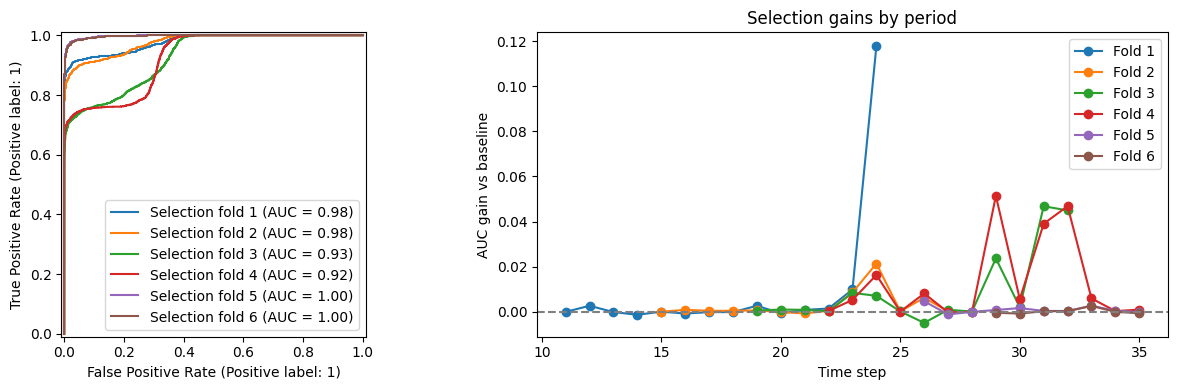

In [9]:
validation_metrics, period_metrics = [], []
for i, ((_, idx), pred) in enumerate(zip(folds, selected_pred), start=1):
    labels, hard = y[idx].astype(int), pred >= 0.5
    validation_metrics.append(dict(fold=i, train_end=FOLDS[i-1][0], valid_start=FOLDS[i-1][1],
        valid_end=FOLDS[i-1][2], rows=len(idx), roc_auc=roc_auc_score(labels, pred),
        baseline_auc=roc_auc_score(labels, baseline_predictions[i-1]),
        gain=roc_auc_score(labels, pred)-roc_auc_score(labels, baseline_predictions[i-1]),
        average_precision=average_precision_score(labels, pred),
        precision_at_0_5=precision_score(labels, hard, zero_division=0),
        recall_at_0_5=recall_score(labels, hard, zero_division=0),
        f1_at_0_5=f1_score(labels, hard, zero_division=0)))
    for step in np.unique(times[idx]):
        mask = times[idx] == step
        period_metrics.append(dict(fold=i, time_step=int(step), rows=int(mask.sum()),
            illicit=int(labels[mask].sum()),
            baseline_auc=roc_auc_score(labels[mask], baseline_predictions[i-1][mask])
            if len(np.unique(labels[mask])) == 2 else np.nan, roc_auc=roc_auc_score(labels[mask], pred[mask])
            if len(np.unique(labels[mask])) == 2 else np.nan))
metrics_frame, periods_frame = pd.DataFrame(validation_metrics), pd.DataFrame(period_metrics)
periods_frame["gain"] = periods_frame.roc_auc - periods_frame.baseline_auc
metrics_frame.to_csv(OUTPUT_DIR / "validation_metrics.csv", index=False)
periods_frame.to_csv(OUTPUT_DIR / "validation_auc_by_period.csv", index=False)
display(metrics_frame)
display(periods_frame)
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for i, ((_, idx), pred) in enumerate(zip(folds, selected_pred), start=1):
    RocCurveDisplay.from_predictions(y[idx], pred, ax=axes[0], name=f"Selection fold {i}")
    group = periods_frame[periods_frame.fold == i]
    axes[1].plot(group.time_step, group.gain, marker="o", label=f"Fold {i}")
axes[1].axhline(0, color="gray", linestyle="--")
axes[1].set(xlabel="Time step", ylabel="AUC gain vs baseline", title="Selection gains by period")
axes[1].legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "validation_performance.png", dpi=160, bbox_inches="tight")
plt.show()

## 6. Final training and submission

Refit the selected recipe through period 35 and average its three seeds. Align probabilities to
`sample_submission.csv`. Export `submission.csv` and reference alternatives; identical predictions
share a file listed in `submission_manifest.json`.

Save configuration, source, models, diagnostics and a ZIP. Graph-risk artifacts include the teacher
and risk features keyed to this dataset's rows; a different graph requires recomputing those features.


In [10]:
def refit_final_models():
    blended = np.zeros(len(test), dtype=np.float64)
    members, fit_log, importance_frames = {}, [], []
    required_specs = {m["spec"]["name"]: m["spec"] for m in recipe["models"]}
    required_specs[recipe["best_single"]] = candidate_specs[recipe["best_single"]]
    required_specs["reference_lgb"] = candidate_specs["reference_lgb"]
    required_specs["recent_reference_lgb"] = candidate_specs["recent_reference_lgb"]
    if ENABLE_WINDOW_EXPERIMENT:
        for window in (16, 20):
            name = WINDOW_EXPERIMENT_NAMES[window]
            required_specs[name] = candidate_specs[name]
    model_dir = OUTPUT_DIR / "models"
    model_dir.mkdir(exist_ok=True)
    for name, spec in required_specs.items():
        mean_pred = np.zeros(len(test), dtype=np.float64)
        for seed in recipe["seeds"]:
            started = time.perf_counter()
            model, rounds, count = fit_for_period(spec, EXPECTED_TRAIN_END, seed)
            pred = predict_model(model, spec, test_row_positions)
            assert np.isfinite(pred).all() and ((pred >= 0) & (pred <= 1)).all()
            mean_pred += pred / len(recipe["seeds"])
            joblib.dump(model, model_dir / f"{name}_seed{seed}.joblib", compress=3)
            fit_log.append(dict(name=name, seed=seed, rounds=rounds, training_rows=count,
                                half_life=spec["half_life"], training_window=spec["window"]))
            if hasattr(model, "feature_importances_"):
                importance_frames.append(pd.DataFrame(dict(model=name, seed=seed,
                    feature=getattr(model, "report_feature_names_", FEATURE_SETS[spec["features"]]), importance=model.feature_importances_)))
            print(f"Fit {name}, seed={seed}, trees={rounds}, rows={count:,}; {(time.perf_counter()-started)/60:.1f} min", flush=True)
            del model
            gc.collect()
        members[name] = mean_pred
    for member in recipe["models"]:
        blended += member["weight"] * members[member["spec"]["name"]]
    final = blended.copy()  # No prediction smoothing in this revision.
    save_json(OUTPUT_DIR / "final_fit_log.json", fit_log)
    if importance_frames:
        pd.concat(importance_frames, ignore_index=True).to_csv(OUTPUT_DIR / "feature_importance.csv", index=False)
    return final, blended, members

def write_submission(predictions, filename):
    assert len(predictions) == len(test) and np.isfinite(predictions).all()
    assert ((predictions >= -1e-12) & (predictions <= 1+1e-12)).all()
    values = pd.Series(np.clip(predictions, 0, 1), index=test["index"].to_numpy())
    submission = sample[["index"]].copy()
    submission["target"] = submission["index"].map(values)
    assert len(submission) == len(sample) and submission.target.notna().all()
    assert submission.target.between(0, 1).all()
    destination = OUTPUT_DIR / filename
    submission.to_csv(destination, index=False, float_format="%.12g")
    check = pd.read_csv(destination)
    assert list(check.columns) == ["index", "target"] and check.shape == sample.shape
    assert check["index"].equals(sample["index"]) and check.target.between(0, 1).all()
    return destination

def compare_submissions(old_path, new_path):
    old, new = pd.read_csv(old_path), pd.read_csv(new_path)
    assert old["index"].is_unique and new["index"].is_unique
    assert set(old["index"]) == set(new["index"])
    previous = old.set_index("index").loc[new["index"], "target"].to_numpy()
    current = new.target.to_numpy()
    delta = np.abs(current - previous)
    return dict(old_file=str(old_path), new_file=str(new_path),
        old_sha256=file_sha256(old_path), new_sha256=file_sha256(new_path),
        byte_identical=file_sha256(old_path) == file_sha256(new_path),
        changed_probabilities=int(np.count_nonzero(delta)),
        changed_above_1e_8=int(np.count_nonzero(delta > 1e-8)),
        max_absolute_change=float(delta.max()), mean_absolute_change=float(delta.mean()))

def same_exported_predictions(first, second):
    # Match the rounding used by write_submission; avoid duplicate Kaggle files.
    first_text = np.array([format(float(p), ".12g") for p in np.clip(first, 0, 1)])
    second_text = np.array([format(float(p), ".12g") for p in np.clip(second, 0, 1)])
    return np.array_equal(first_text, second_text)

def export_submissions(primary, single, baseline, recent_reference, window_reference=None):
    submissions = [("selected", "submission.csv", primary),
                   ("best_single", "submission_best_single.csv", single),
                   ("baseline", "submission_baseline.csv", baseline),
                   ("recent_reference", "submission_recent_reference.csv", recent_reference)]
    if window_reference is not None:
        submissions.append(("window_reference", "submission_window_reference.csv", window_reference))
    written, manifest = [], {}
    for role, filename, pred in submissions:
        assert np.isfinite(pred).all() and ((pred >= -1e-12) & (pred <= 1+1e-12)).all()
        identical = next((entry for entry in written if same_exported_predictions(pred, entry[2])), None)
        if identical is None:
            destination = write_submission(pred, filename)
            written.append((role, destination, pred))
            manifest[role] = dict(file=destination.name, sha256=file_sha256(destination), identical_to=None)
        else:
            manifest[role] = dict(file=identical[1].name, sha256=file_sha256(identical[1]), identical_to=identical[0])
    save_json(OUTPUT_DIR / "submission_manifest.json", manifest)
    return manifest

def archive_run(run_dir):
    run_dir = Path(run_dir).resolve()
    # Archive goes beside its source directory, never inside itself.
    return Path(shutil.make_archive(str(run_dir), "zip", root_dir=run_dir))

test_pred, test_unsmoothed, test_members = refit_final_models()
window_reference_pred = None
if ENABLE_WINDOW_EXPERIMENT:
    window_reference_pred = (0.5 * test_members[WINDOW_EXPERIMENT_NAMES[16]]
                             + 0.5 * test_members[WINDOW_EXPERIMENT_NAMES[20]])
manifest = export_submissions(test_pred, test_members[recipe["best_single"]], test_members["reference_lgb"],
                              test_members["recent_reference_lgb"], window_reference_pred)
submission_path = OUTPUT_DIR / manifest["selected"]["file"]
baseline_path = OUTPUT_DIR / manifest["baseline"]["file"]
comparison_to_baseline = compare_submissions(baseline_path, submission_path)
save_json(OUTPUT_DIR / "comparison_to_baseline.json", comparison_to_baseline)
comparison_to_recent_reference = compare_submissions(
    OUTPUT_DIR / manifest["recent_reference"]["file"], submission_path)
save_json(OUTPUT_DIR / "comparison_to_recent_reference.json", comparison_to_recent_reference)
comparison_to_window_reference = None
if ENABLE_WINDOW_EXPERIMENT:
    comparison_to_window_reference = compare_submissions(
        OUTPUT_DIR / manifest["window_reference"]["file"], submission_path)
    save_json(OUTPUT_DIR / "comparison_to_window_reference.json", comparison_to_window_reference)

test_details = test[["index", "txId", "time_step"]].copy()
test_details["target"], test_details["unsmoothed"] = test_pred, test_unsmoothed
for name, pred in test_members.items():
    test_details[name] = pred
if window_reference_pred is not None:
    test_details["window_reference"] = window_reference_pred
test_details.to_csv(OUTPUT_DIR / "test_prediction_details.csv", index=False)
elapsed = (time.perf_counter()-START_TIME)/60
save_json(OUTPUT_DIR / "run_summary.json", dict(version=NOTEBOOK_VERSION, run_id=RUN_ID,
    elapsed_minutes_before_archive=elapsed, candidate_count=len(records)+len(joint_records),
    single_candidate_count=len(records), ensemble_trial_count=len(joint_records),
    selection_score=recipe["selection_score"],
    selection_score_type=recipe["selection_score_type"], selection_status=recipe["selection_status"],
    validation_windows=validation_metrics,
    submission=submission_path.name, submissions=manifest,
    submission_sha256=file_sha256(submission_path), comparison_to_baseline=comparison_to_baseline,
    comparison_to_recent_reference=comparison_to_recent_reference,
    comparison_to_window_reference=comparison_to_window_reference,
    score_type="selection; no untouched holdout", kaggle_score=None))
run_notes = [f"# {RUN_ID}", "", "Upload submission.csv to Kaggle.", "",
    f"Version: {NOTEBOOK_VERSION}", f"Single configurations screened: {len(records)}; ensemble trials: {len(joint_records)}",
    f"Selection objective (weighted AUC minus stability penalty; not Kaggle AUC): {recipe['selection_score']:.6f}",
    f"Selection status: {recipe['selection_status']}",
    f"Recency mode: {RECENCY_MODE}; searched half-lives: {HALF_LIFE_CHOICES}",
    "See recency_comparison.csv and training_weights_by_period.csv for the original-reference comparisons.",
    "See window_comparison.csv and window_training_counts.csv for the recent-reference comparisons.",
    f"Window experiment enabled: {ENABLE_WINDOW_EXPERIMENT}",
    "When enabled, window_experiment_comparison.csv and window_experiment_blends.csv show the three-seed experiment.",
    "The window_reference manifest role is the freshly refitted 50/50 average of 16- and 20-period models.",
    f"Windows selected for direct ensemble tuning: {selected_tuning_windows}",
    "See window_selection.json, optuna_lgb_ensemble_focused_trials.json, optuna_lgb_ensemble_broad_trials.json, and ensemble_tuning_comparison.csv.",
    "Duplicate configurations and recipes are recorded in candidate_aliases.json and ensemble_aliases.json.",
    f"Required gain over the fixed 16/20 reference: {MIN_REFERENCE_IMPROVEMENT}",
    f"Final seeds: {FINAL_SEEDS}", "", "Selected models:"]
run_notes += [f"- {member['spec']['name']}: weight {member['weight']:.6f}" for member in recipe["models"]]
run_notes += ["", f"Graph smoothing: {recipe['graph_smoothing_alpha']}", "",
    f"Changed probabilities vs same-run baseline: {comparison_to_baseline['changed_probabilities']}",
    "", "Alternative submission files (duplicates share the same filename):"]
run_notes += [f"- {role}: {entry['file']}" for role, entry in manifest.items()]
run_notes += ["", "No fresh untouched holdout exists; all local metrics are selection statistics.",
    "Reproduce from scratch with the included notebook, requirements-run.txt, and the four original CSVs.",
    "No saved model, old study, or earlier predictions are read during a fresh run.",
    "See selection_explanation.json and ensemble_comparison.csv for the final decision.",
    "The CSVs are not in this archive; input_hashes.json identifies the exact inputs."]
(OUTPUT_DIR / "RUN_README.md").write_text("\n".join(run_notes) + "\n", encoding="utf-8")
save_json(OUTPUT_DIR / "run_status.json", dict(status="complete", completed_candidates=len(records)+len(joint_records),
    completed_single_candidates=len(records), completed_ensemble_trials=len(joint_records)))
archive_path = archive_run(OUTPUT_DIR)
if "window_reference" in manifest and manifest["window_reference"]["file"] == manifest["selected"]["file"]:
    print("Selected CSV equals the freshly fitted 16/20 window reference; this run produced no new submission predictions.")
elif manifest["baseline"]["file"] == manifest["selected"]["file"]:
    print("Selected CSV equals this run's reference. Do not resubmit if you already submitted the identical file.")
else:
    print("CANDIDATE CSV FOR KAGGLE:", submission_path)
print("Saved primary CSV:", submission_path)
print("Complete run ZIP:", archive_path)
print("Changed probabilities vs baseline:", comparison_to_baseline["changed_probabilities"], "of", len(test))
print(f"Total elapsed time: {(time.perf_counter()-START_TIME)/60:.1f} minutes")
display(pd.DataFrame(manifest).T)
display(pd.read_csv(submission_path).head())

Fit graph_risk_reference, seed=42, trees=132, rows=15,721; 0.0 min
Fit graph_risk_reference, seed=137, trees=132, rows=15,721; 0.0 min
Fit graph_risk_reference, seed=2026, trees=132, rows=15,721; 0.0 min
Fit reference_lgb, seed=42, trees=132, rows=31,235; 0.0 min
Fit reference_lgb, seed=137, trees=132, rows=31,235; 0.0 min
Fit reference_lgb, seed=2026, trees=132, rows=31,235; 0.0 min
Fit recent_reference_lgb, seed=42, trees=132, rows=13,246; 0.0 min
Fit recent_reference_lgb, seed=137, trees=132, rows=13,246; 0.0 min
Fit recent_reference_lgb, seed=2026, trees=132, rows=13,246; 0.0 min
Fit window_lgb_w20_h32, seed=42, trees=132, rows=15,721; 0.0 min
Fit window_lgb_w20_h32, seed=137, trees=132, rows=15,721; 0.0 min
Fit window_lgb_w20_h32, seed=2026, trees=132, rows=15,721; 0.0 min
CANDIDATE CSV FOR KAGGLE: c:\Users\limyu\Desktop\y4s1\BT4012\kaggle_comp\outputs\fresh_search_20261018_132550_385554\submission.csv
Saved primary CSV: c:\Users\limyu\Desktop\y4s1\BT4012\kaggle_comp\outputs\fresh

,file,sha256,identical_to
selected,submission.csv,668c0c8efd06587af3703eea47b54719b7d34ba544fc27...,None
best_single,submission.csv,668c0c8efd06587af3703eea47b54719b7d34ba544fc27...,selected
baseline,submission_baseline.csv,2033bd43eb5b2b7288fc4ad51f778e9e37b31cab0fe887...,None
recent_reference,submission_recent_reference.csv,66aa2cb9c151aeac65734e447cea8bc1cb4c2bef64d935...,None
window_reference,submission_window_reference.csv,3852f7eaa9e3552e379d5fc9fa150a806bdac428e0974d...,None


,index,target
0,0,0.002451
1,1,0.008115
2,2,0.004269
3,3,0.002546
4,4,0.001684


## 7. Interpretation

Compare the selected model with simpler references and report both validation and Kaggle results.
Chronological validation, leakage checks and reproducibility support the analysis, but reused
development windows and heuristic labels limit generalization claims. More trials or models do
not guarantee improvement. Detailed settings and output descriptions are in `README.md`.
